# Delayed entry after the start of a move: does observing it help?

**Pilot on `btcusdt_v2`** · Binance USDⓈ-M BTCUSDT perpetual · decisions on `time_1m`, execution on a 1-second trade tape · forward test February to October 2026 · `EXPLORATORY`

## Summary

**Question.** After a large one-minute impulse, does watching the next 5 to 15 minutes make the direction of the eventual barrier more predictable, and does that help choose a delayed entry, especially when combined with a forecast that a barrier will be reached?

**Answer: no.** Observation makes barrier **attainment** a little more predictable, but it adds no directional information beyond geometry. The models do not pick entries with better gross returns, and no execution or cost level tested makes them profitable.

| Question | Result | Key evidence (test, Feb–Oct 2026, 2,046 events) |
|---|---|---|
| Q1. Directional discrimination and calibration | **Not supported** | After observation, the directional AUC of about 0.77 comes entirely from geometry: the closed-form Brownian baseline alone reaches 0.776. Every learned model is slightly **worse** than the calibrated geometric baseline on direction (full model −0.007 nats [−0.016, +0.001]). The three-way gain of the full model over the baseline is −0.003 [−0.007, +0.003] |
| Q1b. Does observation help? | **Criterion met as written, but not meaningful** | The full model's directional loss against geometry is smaller after observation than at `τ = 0` (+0.011 [+0.002, +0.019]). It is still negative at both times, so observation makes the model less harmful, not useful |
| Order flow beyond geometry and volatility | **No** | `B+FLOW` over `B` on delayed decisions: +0.001 [−0.003, +0.005], inside the placebo range (max +0.0035) |
| Attainment forecast beyond the features | **No** | `F+HIT` over `F`: +0.0005 nats. As a replacement for volatility features it loses information (−0.012). As a post-hoc gate it does not help the side choice |
| Attainment itself | **Predictable, as before** | Attainment AUC 0.68 against 0.62 for geometry. The models are better calibrated than geometry on "neither barrier" (ECE 0.017 against 0.038) |
| Q2. Better expected gross? | **No. The full model is worse** | Sequential policy: −4.6 bps per trade, below the baseline model (−4.6 [−7.9, −1.2] difference), below a random side, and at the 0.5th percentile of random row selection. Score deciles show no gross gradient; rank correlation with the realised return is −0.006 |
| Enough movement after entry? | **Yes in size, no in direction** | Surviving trades still move about 21 to 29 bps in absolute terms, and execution drag is under 1 bp. There is room to pay 10 bps, but nothing tells which way |
| Q3. Economic usefulness | **None found** | Best gross per trade among the models is +1.2 bps (baseline, neutral execution), not distinguishable from zero. The full model is negative at zero cost under every execution variant |

**Should the multi-model architecture be tested next?** **No, not on this event definition and decision clock.** Specialised barrier models would refine attainment, which is already predictable and not the bottleneck. Stacking an out-of-sample attainment forecast added nothing. There is no directional signal for a more complex architecture to amplify.

**How far this reaches.** One event rule, one barrier width, one 60-minute horizon, decisions at minute closes only, BTCUSDT on Binance, February to October 2026. All of it has been explored before, so the study is `EXPLORATORY`. Section 2 was fixed before any outcome was computed; section 13 is `POST-HOC`.

**How to read this notebook.** Sections 1–2 give the context and design. Sections 3–8 build the data, events, engine, panel, and harness. Sections 9–12 answer the three questions. Section 13 has the post-hoc diagnostics, and section 14 the final answer.

## 1. What earlier work established, and what is new here

| Source | Finding | Consequence for this design |
|---|---|---|
| `btcusdt_v2_predictive_exploration.ipynb` | Volatility is very predictable from price, volume, and time of day. Direction has one small, fast signal: top-of-book imbalance, about 0.67 bps, mostly within 30 s. Mild reversal at 15–30 minutes | Expect barrier attainment to be predictable and direction to be hard. Order-book features are measured at the minute, which is slower than the imbalance effect |
| `btcusdt_v2_metalabeling_pilot.ipynb`, `..._multistrategy.ipynb` | Meta-models predict **whether** a barrier is hit (AUC about 0.69), not **which** one (about 0.50). AUC on a net label rewards volatility, not money. Filters must be compared with random filters of equal retention | Separate direction from attainment explicitly. Judge selection by gross return per trade against matched controls, not by AUC |
| `..._edge_experiment.ipynb` | A secondary model only adds value when the primary's edge varies with observable state | The question here is exactly whether direction becomes observable **after** part of the move |
| `docs/DATASET_V2.md`, `docs/LIMITATIONS.md`, `docs/VALIDITY_MAP.md` | Features are as-of `eval_time`, before the decision. Book state must be valid (`book_state` 0 or 9). Strict windows can be missing in stress. One retrospective book incident | Same eligibility rules and incident exclusion as before |

**What has not been tested:** whether the direction of the eventual barrier becomes more predictable once a few minutes of the move have been seen, and whether a delayed entry, priced honestly after latency, still has enough room to pay.

**All periods through October 2026 have already been explored.** This study is `EXPLORATORY`. Decisions fixed before evaluation are in section 2 and are not changed afterwards. Diagnostics added after seeing results are marked `POST-HOC`.

## 2. Design, fixed before any outcome was computed

### 2.1 Observation events

**Rule.** At each one-minute close, compute the one-minute log return divided by the trailing per-minute volatility over the previous 240 minutes, excluding the current minute. If its absolute value is **at least 3**, an observation event starts at that close, with direction `e` equal to the sign of the move. The next event can start only 60 minutes later.

**Why this rule.** A large one-minute impulse is the simplest causal marker of "the beginning of a potential move": it is observable at the bar close, scale-free, and needs no fitted parameters. The threshold of 3 was chosen from event **frequency only** (about 8.6 events per day with spacing, against 11.8 at 2.5 and 4.5 at 4), before any outcome was computed. The 60-minute spacing equals the horizon, so **outcome windows of different events never overlap.**

**An event does not open a position.** It starts an observation window.

### 2.2 Barriers, horizon, and decision times

| Item | Choice |
|---|---|
| Anchor price `P0` | Close of the impulse minute |
| Barriers | `P0·exp(±w)`, `w = 1.0 × σ × √60`, with σ the pre-event per-minute volatility |
| Horizon | 60 minutes from the event start, fixed |
| Anchoring | **Barriers stay anchored to the original event.** They are not reset at entry. The remaining horizon at decision `τ` is `60 − τ` minutes |
| Decision times | `τ` = 0, 5, 10, 15 minutes after the event start. Fixed in advance; no other times are evaluated |
| Orientation | Everything is expressed in the event frame: the **continuation barrier** is in the impulse direction, the **reversal barrier** opposite |

Anchoring keeps one geometry per event, so a delayed decision faces a **shifted** geometry: if price has already moved toward the continuation barrier, that barrier is nearer and the payoff for continuing is smaller.

### 2.3 Labels

At decision `τ`, an event **survives** if no barrier was touched before the decision time. For survivors, the label is which barrier is touched first **after** the decision, on the 1-second tape: continuation-first, reversal-first, or neither before expiry. Seconds where both barriers are touched together are ambiguous; they are counted and dropped from the classification label.

A second target is the **frictionless oriented return** from the decision price to the barrier or expiry close, in barrier units. It feeds the expected-return model.

**Decision frequency versus execution resolution.** Decisions happen only at minute closes on `time_1m`. Barrier attainment, entries, and exits are resolved on a 1-second high/low/last tape built from every trade.

### 2.4 Execution: delayed entry is priced honestly

| Item | Rule |
|---|---|
| Latency | The order reaches the market in the first whole second at or after decision + 1 s |
| Entry | Worst trade price in that second. No fill within 5 s: no trade |
| Resolved before entry | If either barrier is touched between the decision and the entry second, the trade is cancelled and counted as such |
| Exits | At the **anchored** barriers or at the original expiry. Target fills at the barrier. Stop fills at the worst price in the second. Stop wins ties |
| Gross | `side × (exit / entry − 1)`, from the actual entry price. Movement before entry is not captured |
| Variants (section 9) | Neutral: last price in the second, stop at the barrier. Slow: 5 s latency, worst price |
| Costs | Reported gross, then with 0, 2, 4, 7, 10 bps round trip |

### 2.5 Models and feature sets

Two heads share each feature set:

* **Joint outcome model:** a three-class LightGBM (continuation-first, reversal-first, neither). It gives probabilities.
* **Expected-return model:** a LightGBM regression of the frictionless oriented return. It gives the side and the ranking for trading.

Decision times are pooled into one model, with `τ` and the remaining time as inputs. Settings are fixed and conservative, not tuned. Earlier notebooks found that tuning did not help at this signal level.

| Set | Content | Role |
|---|---|---|
| `G` | Driftless Brownian motion between the two barriers, from current distances, remaining time, and pre-event volatility. Closed-form, no fitting | **Geometric null.** Its expected return is zero by construction |
| `Gcal` | `G` recalibrated by a multinomial logit on its log-probabilities | Strong geometric baseline |
| `B` | Barrier distances, remaining time, volatility (pre-event, post-event realized, 15-minute), activity, time of day | Baseline required by the brief |
| `B+PATH` | Adds impulse size, excursions since the event, path efficiency, last-minute move, pre-event trend | Price-path information |
| `B+FLOW` | Adds updated trade flow and order-book features at the decision minute | Order-flow information |
| `F` | `B + PATH + FLOW` | Full model |
| `F+HIT`, `B+HIT` | Add an **out-of-sample** barrier-attainment forecast from a separate binary model trained on the same features | The controlled test of the attainment forecast |
| `GP+HIT` | Geometry, path, and flow, with the attainment forecast **replacing** the volatility and activity features | Does the forecast summarise volatility, or add to it? |

All direction-carrying features are multiplied by `e`, so positive means "in the direction of the impulse".

### 2.6 Validation

| Choice | Decision |
|---|---|
| Outer | Walk-forward, 3 blocks: Feb–Apr, May–Jul, Aug–Oct 2026. Training uses events whose 60-minute window ends at least 24 h before the block. The October 2025 crash is excluded from training |
| Grouping | All decision times of one event are always in the same fold. Events never overlap in time |
| Inner | Purged 4-fold on training events, grouped by event, with a 24 h embargo. It produces the **out-of-sample** attainment forecasts used as training inputs for `F+HIT` and the others, and the out-of-fold scores used to set trading thresholds |
| Uncertainty | Moving-block bootstrap of 5 calendar days, the same draws for every model, so paired differences inherit the dependence |

### 2.7 Position policy

One position at a time, one unit of notional, no leverage. Because events are at least 60 minutes apart and a trade ends by the event's expiry, a trade never overlaps another event.

| Policy | Rule |
|---|---|
| `IMMEDIATE` | Trade at `τ = 0` only |
| `FIXED τ` | Trade only at that decision time, if the event survives |
| `SEQUENTIAL` | Check `τ` = 0, 5, 10, 15 in order; enter at the first one that passes the threshold; at most one trade per event |

The side is the sign of the expected-return model. A row passes if its absolute expected return is above a threshold set on **training out-of-fold scores**, so that about **30% of events** are traded. Thresholds never see the test block.

**Controls at the same retention:** the same selected rows with a random side; the model's side on randomly selected rows (same count per month); always continuation; always reversal; the `B` model through the same policy; and a **nearer-barrier rule** (trade toward whichever barrier is closer), which has a high win rate by construction.

### 2.8 The three questions and the decision rules

| Question | Supported if |
|---|---|
| Q1. Better directional discrimination and calibration? | Pooled delayed decisions (`τ` = 5, 10, 15): `F` beats `B` in multiclass log loss with a 95% interval above zero and in at least 2 of 3 blocks; and the directional log loss among resolved events beats `Gcal` |
| Q1b. Does observation help? | `F`'s directional gain over `Gcal` is larger at delayed decisions than at `τ = 0`, with an interval above zero |
| Q1c. Does the attainment forecast add? | `F+HIT` beats `F` in log loss with an interval above zero |
| Q2. Better expected gross, not just win rate? | `SEQUENTIAL F` gross per trade above the random-selection control **and** above the `B` policy, paired intervals above zero |
| Q3. Economically useful? | Reported as the cost and execution levels at which net per trade stays above zero. No verdict threshold |

**What I expect, written before running.** Barrier attainment will stay predictable. The impulse frame will show a small reversal tendency at `τ = 0`, consistent with the earlier 15–30 minute reversal. I expect order flow to add little beyond the price path at the minute scale. I expect the attainment forecast to add nothing beyond features already in the model. I expect delayed entries to give up much of the remaining move to the anchored barrier, so economic value will be hard to find.

## 3. Setup

**Environment.** Conda environment `disertatie`. Heavy work runs in forked worker processes; LightGBM runs single-threaded inside each, because concurrent LightGBM threads segfaulted in an earlier notebook.

**What it touches.** It reads `derived/datasets/btcusdt_v2` (`time_1m` only) and `derived/canonical/trades`. It writes nothing except itself. The last cell checks the sources are unchanged.

**`META_DRY_RUN=1`** moves the test blocks into development months, for debugging without touching test outcomes. **`META_CACHE`** caches heavy stages.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMBA_NUM_THREADS"):
    os.environ[_v] = "1"
import hashlib, json, multiprocessing as mp, pickle, platform, resource, sys, time, warnings
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib as mpl
import matplotlib.pyplot as plt
import lightgbm as lgb
import numba
import scipy
import sklearn
import statsmodels
from numba import njit
from scipy import stats
from scipy.special import expit, logit, softmax
from sklearn.linear_model import LogisticRegression

T0 = time.time()
SEED = 20261108
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

def find_repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data/cryptohftdata/derived/datasets/btcusdt_v2/manifest.json").exists():
            return p
    raise FileNotFoundError("Run this notebook from inside the QuantForge repository.")

ROOT = find_repo_root()
CHDDS = ROOT / "data/cryptohftdata"
DATA = CHDDS / "derived/datasets/btcusdt_v2"
TRADES = CHDDS / "derived/canonical/trades"
sys.path.insert(0, str(CHDDS))
from chdds.dataset import incident_rows

man = json.loads((DATA / "manifest.json").read_text())
DRY_RUN = os.environ.get("META_DRY_RUN") == "1"
CACHE = os.environ.get("META_CACHE")
WORKERS = int(os.environ.get("META_WORKERS", "12"))

def source_fingerprint():
    files = sorted(DATA.rglob("*.parquet")) + [DATA / "manifest.json"] + sorted(TRADES.glob("*.parquet"))
    return (len(files), sum(f.stat().st_size for f in files), max(f.stat().st_mtime_ns for f in files))
FINGERPRINT_START = source_fingerprint()

def cached(name, fn):
    if CACHE:
        p = Path(CACHE) / f"{name}{'_dry' if DRY_RUN else ''}.pkl"
        if p.exists():
            return pickle.loads(p.read_bytes())
    out = fn()
    if CACHE:
        Path(CACHE).mkdir(parents=True, exist_ok=True)
        p.write_bytes(pickle.dumps(out, protocol=5))
    return out

def pmap(fn, items, workers=None):
    # Fork pool: workers inherit read-only globals. Results keep input order. A worker crash raises instead of hanging.
    items = list(items); out = [None] * len(items)
    with ProcessPoolExecutor(workers or WORKERS, mp_context=mp.get_context("fork")) as ex:
        futs = {ex.submit(fn, it): i for i, it in enumerate(items)}
        for f in as_completed(futs):
            out[futs[f]] = f.result()
    return out

C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", red="#e34948", purple="#7a5bd0", gold="#c99a1e")
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110, "font.size": 10, "font.family": "sans-serif",
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True, "lines.linewidth": 1.8, "legend.frameon": False, "legend.fontsize": 9})
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 200)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | lightgbm {lgb.__version__} | scikit-learn {sklearn.__version__} | numba {numba.__version__}")
print(f"Dataset {DATA.name}, created {man['created_utc']}, book mode {man['book_provenance']['book_mode']} | workers {WORKERS} | dry run {DRY_RUN}")

Python 3.11.13 | pandas 2.3.3 | numpy 2.0.2 | lightgbm 4.6.0 | scikit-learn 1.7.2 | numba 0.64.0
Dataset btcusdt_v2, created 2026-11-05T20:01:10Z, book mode rebuilt | workers 14 | dry run False


In [2]:
UTC = "UTC"
TRAIN_START = pd.Timestamp("2025-07-22", tz=UTC)
DATA_END = pd.Timestamp("2026-11-01", tz=UTC)
CRASH_START, CRASH_END = pd.Timestamp("2025-10-09", tz=UTC), pd.Timestamp("2025-10-12", tz=UTC)
BLOCKS = [("2026-02-01", "2026-05-01"), ("2026-05-01", "2026-08-01"), ("2026-08-01", "2026-11-01")]
if DRY_RUN:
    BLOCKS = [("2025-11-15", "2025-12-15"), ("2025-12-15", "2026-02-01")]
BLOCKS = [(pd.Timestamp(a, tz=UTC), pd.Timestamp(b, tz=UTC)) for a, b in BLOCKS]
FIRST_TEST, TEST_END = BLOCKS[0][0], BLOCKS[-1][1]

Z_TH = 3.0                    # impulse threshold, in pre-event per-minute volatility units
VOL_WIN = 240                 # minutes in the pre-event volatility estimate
T_MIN = 60                    # horizon and minimum spacing between events
TAUS = [0, 5, 10, 15]         # decision times after the event start, minutes
K_BARRIER = 1.0
LATENCY_S, MAX_WAIT_S = 1, 5
COSTS = [0, 2, 4, 7, 10]
FRESH_MS = 10_000
EMBARGO_NS = 24 * 3600 * 10**9
INNER_K = 4
RETENTION = 0.30
BOOT_REPS, BOOT_BLOCK_D = 1000, 5
N_PERM = 3 if DRY_RUN else 12
CTRL_REPS = 200
LGB_PARAMS = dict(learning_rate=0.03, num_leaves=7, max_depth=3, min_data_in_leaf=60, feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1,
                  lambda_l2=10.0, max_bin=63, num_threads=1, deterministic=True, force_row_wise=True, verbosity=-1)
LGB_ROUNDS = 250
SEEDS = (0, 1, 2)
print(pd.Series(dict(blocks=[f"{a.date()}..{b.date()}" for a, b in BLOCKS], z_threshold=Z_TH, horizon_min=T_MIN, taus=TAUS, barrier_k=K_BARRIER, latency_s=LATENCY_S, retention=RETENTION)).to_string())

blocks         [2026-02-01..2026-05-01, 2026-05-01..2026-08-0...
z_threshold                                                  3.0
horizon_min                                                   60
taus                                              [0, 5, 10, 15]
barrier_k                                                    1.0
latency_s                                                      1
retention                                                    0.3


## 4. Data: the one-minute decision grid and the one-second execution tape

**Decision grid.** `time_1m` rows, one per minute. Every feature is as-of the row's `eval_time`, one nanosecond before the minute close, which is the decision time.

**Execution tape.** The high, low, and last trade price of every second, built from all canonical trades. Seconds without trades stay empty, so a feed gap is visible and never filled with a stale price.

In [3]:
SEC0 = int(pd.Timestamp("2025-06-28", tz=UTC).timestamp())
N_SEC = int(pd.Timestamp("2026-11-02", tz=UTC).timestamp()) - SEC0

@njit
def tape_add(sec, px, hi, lo, cl):
    for i in range(sec.size):
        s = sec[i]; p = px[i]
        if hi[s] == 0:
            hi[s] = p; lo[s] = p
        else:
            if p > hi[s]: hi[s] = p
            if p < lo[s]: lo[s] = p
        cl[s] = p

def build_tape():
    hi = np.zeros(N_SEC, np.int32); lo = np.zeros(N_SEC, np.int32); cl = np.zeros(N_SEC, np.int32)
    for f in sorted(TRADES.glob("*.parquet")):
        tb = pq.read_table(f, columns=["recv_ns", "price_e2"])
        tape_add(tb["recv_ns"].to_numpy() // 10**9 - SEC0, tb["price_e2"].to_numpy().astype(np.int32), hi, lo, cl)
    return hi, lo, cl

t_ = time.time()
HI, LO, CL = cached("tape", build_tape)
print(f"Tape ready in {time.time() - t_:.0f} s: {N_SEC:,} seconds, {np.mean(HI[int(TRAIN_START.timestamp()) - SEC0:int(DATA_END.timestamp()) - SEC0] > 0):.2%} with at least one trade in the study window.")

COLS = '''decision_time_ns t_start_ns eval_time_ns complete feed_complete last_trade_age_ms book_state bar_close funding_rate_asof
notional_2m_usdt notional_15m_usdt trade_count_15m rv_trade_15m_grid1s hour_of_day_sin hour_of_day_cos
tfi_ratio_30s tfi_ratio_2m tfi_ratio_15m count_imbalance_2m signed_large_flow_15m_usdt
ofi_norm_30s ofi_norm_2m mlofi_norm_l5_30s qi_1 qi_5bps qi_25bps pressure_net_5bps_2m
cost_buy_1000000usdt_atmid_bps cost_sell_1000000usdt_atmid_bps tw_spread_bps_2m depth_bid_10bps_btc depth_ask_10bps_btc'''.split()

def spec_id(name):
    return next(k for k, v in man["bar_sets"].items() if v["name"] == name)

def load_grid():
    files = sorted((DATA / spec_id("time_1m")).glob("*.parquet"))
    return pd.concat([pq.read_table(f, columns=COLS).to_pandas() for f in files], ignore_index=True)

G1 = cached("grid", load_grid)
tdec = G1["decision_time_ns"].to_numpy()
assert (np.diff(tdec) == 60 * 10**9).all(), "time_1m must be a gap-free minute grid"
print(f"time_1m grid: {len(G1):,} minutes from {pd.Timestamp(tdec[0], tz=UTC)} to {pd.Timestamp(tdec[-1], tz=UTC)}, no missing minutes.")

Tape ready in 117 s: 42,508,800 seconds, 95.47% with at least one trade in the study window.


time_1m grid: 707,040 minutes from 2025-06-28 00:01:00+00:00 to 2026-11-01 00:00:00+00:00, no missing minutes.


## 5. Observation events and their geometry

The impulse is measured against volatility from the 240 minutes **before** the current minute, so the impulse minute never enters its own scale. The spacing rule is applied to all impulses before any eligibility filter, so it is purely mechanical and label-free.

In [4]:
safe_log = lambda x: np.log(np.where(x > 0, x, np.nan))
px = G1["bar_close"].where(G1["last_trade_age_ms"] <= FRESH_MS).to_numpy()
r1 = np.concatenate([[np.nan], np.diff(np.log(px))])
r2s = pd.Series(r1 ** 2)
SIG_PRE = np.sqrt(r2s.shift(1).rolling(VOL_WIN, min_periods=int(.75 * VOL_WIN)).mean()).to_numpy()
SIG_24 = np.sqrt(r2s.shift(1).rolling(1440, min_periods=1080).mean()).to_numpy()
Z1 = r1 / SIG_PRE
def rel(x):
    lx = pd.Series(safe_log(np.asarray(x, float)))
    return (lx - lx.shift(1).rolling(7 * 1440, min_periods=1440).mean()).to_numpy()
REL = {"rel_notional_2m": rel(G1["notional_2m_usdt"]), "rel_notional_15m": rel(G1["notional_15m_usdt"]), "rel_trades_15m": rel(G1["trade_count_15m"]),
       "rel_spread_2m": rel(G1["tw_spread_bps_2m"]), "rel_depth_10bps": rel(G1["depth_bid_10bps_btc"] + G1["depth_ask_10bps_btc"])}

ok_row = (G1["complete"].to_numpy() == 1) & (G1["feed_complete"].to_numpy() == 1) & np.isfinite(Z1)
in_win = (tdec >= TRAIN_START.value) & (tdec < DATA_END.value - (T_MIN + 1) * 60 * 10**9)
cand = np.flatnonzero(ok_row & in_win & (np.abs(Z1) >= Z_TH))
picked, last = [], -(10**18)
for i in cand:
    if tdec[i] - last >= T_MIN * 60 * 10**9:
        picked.append(i); last = tdec[i]
I0 = np.array(picked)
EV = pd.DataFrame({"i0": I0, "t0_ns": tdec[I0], "e": np.sign(Z1[I0]).astype(int), "z": Z1[I0], "sig": SIG_PRE[I0], "p0": px[I0]})
EV["w"] = K_BARRIER * EV["sig"] * np.sqrt(T_MIN)
EV["up"], EV["dn"] = EV["p0"] * np.exp(EV["w"]), EV["p0"] * np.exp(-EV["w"])
EV["t0"] = pd.to_datetime(EV["t0_ns"], utc=True); EV["month"] = EV["t0"].dt.strftime("%Y-%m"); EV["day"] = EV["t0"].dt.floor("D")
bs = G1["book_state"].to_numpy()
elig = (np.isin(bs[I0], [0, 9]) & G1["tfi_ratio_15m"].notna().to_numpy()[I0] & G1["ofi_norm_2m"].notna().to_numpy()[I0] & np.isfinite(EV["sig"].to_numpy()) & np.isfinite(EV["p0"].to_numpy()))
inc = incident_rows(EV["t0_ns"].to_numpy() - 15 * 60 * 10**9, EV["t0_ns"].to_numpy() + T_MIN * 60 * 10**9, man["quality_incidents"])
EV["eligible"] = elig & ~inc
EV["crash"] = (EV["t0_ns"] + T_MIN * 60 * 10**9 >= CRASH_START.value) & (EV["t0_ns"] < CRASH_END.value)
assert (np.diff(EV["t0_ns"].to_numpy()) >= T_MIN * 60 * 10**9).all()
days = (DATA_END - TRAIN_START).days
print(f"{len(EV):,} events ({len(EV) / days:.1f} per day), {EV['eligible'].mean():.1%} eligible. Continuation-up share {np.mean(EV['e'] > 0):.1%}. Median barrier distance {1e4 * EV['w'].median():.0f} bps; median impulse {EV['z'].abs().median():.2f} sigma.")

4,012 events (8.6 per day), 88.0% eligible. Continuation-up share 50.4%. Median barrier distance 31 bps; median impulse 3.61 sigma.


**What this shows.** The rule produces about 8.6 events per day, 88% eligible, evenly split between up and down impulses. The median barrier is 31 bps away from the anchor, which is three times a 10 bps round trip. A typical impulse is 3.6 times the pre-event one-minute volatility.

### Resolution on the tape: survival, labels, and executable trades

One numba pass per event:

1. Finds the first second each anchored barrier is touched (high at or above the upper barrier, low at or below the lower one) until expiry.
2. For each decision time, records survival, the label after the decision, and the frictionless return from the decision price.
3. Simulates the executable trade on both sides under three execution variants.

Status codes for a trade: `0` the event had already resolved before the decision; `1` a barrier was touched between decision and entry, so the order is cancelled; `2` no print within the fill window; `3` traded.

In [5]:
V_NAMES = ["base: 1 s, worst price", "neutral: 1 s, last price", "slow: 5 s, worst price"]
V_LAT = np.array([1, 1, 5]); V_MODE = np.array([0, 1, 0])     # mode 0: worst price in the second; mode 1: last price, stop at the barrier
SURV_NO, ST_CANCEL, ST_NOFILL, ST_TRADE = 0, 1, 2, 3

@njit
def last_price_before(s, cl, hi):
    # Last trade price strictly before second s.
    k = s - 1
    while k >= 0 and hi[k] == 0:
        k -= 1
    return float(cl[k]) if k >= 0 else np.nan

@njit
def resolve_events(s0, up, dn, horizon_s, taus_s, lat, mode, max_wait, hi, lo, cl):
    n = s0.size; nt = taus_s.size; nv = lat.size
    ft_up = np.full(n, -1, np.int64); ft_dn = np.full(n, -1, np.int64)
    p_dec = np.full((n, nt), np.nan); exit_fric = np.full((n, nt), np.nan)
    gross = np.full((n, nt, 2, nv), np.nan)          # side index 0 = long, 1 = short
    status = np.zeros((n, nt, 2, nv), np.int8)
    reason = np.zeros((n, nt, 2, nv), np.int8)       # 1 target, 2 stop, 3 time
    for i in range(n):
        sx = s0[i] + horizon_s                        # expiry: seconds [s0, sx) belong to the window
        U = up[i]; L = dn[i]
        for s in range(s0[i], sx):
            if hi[s] == 0:
                continue
            if ft_up[i] < 0 and hi[s] >= U:
                ft_up[i] = s
            if ft_dn[i] < 0 and lo[s] <= L:
                ft_dn[i] = s
            if ft_up[i] >= 0 and ft_dn[i] >= 0:
                break
        first = sx + 1
        if ft_up[i] >= 0: first = ft_up[i]
        if ft_dn[i] >= 0 and ft_dn[i] < first: first = ft_dn[i]
        pexp = last_price_before(sx, cl, hi)
        for j in range(nt):
            d = s0[i] + taus_s[j]
            if first < d:
                continue                              # resolved before this decision
            p_dec[i, j] = last_price_before(d, cl, hi)
            if ft_up[i] >= 0 and (ft_dn[i] < 0 or ft_up[i] < ft_dn[i]):
                exit_fric[i, j] = U
            elif ft_dn[i] >= 0 and (ft_up[i] < 0 or ft_dn[i] < ft_up[i]):
                exit_fric[i, j] = L
            elif ft_up[i] < 0 and ft_dn[i] < 0:
                exit_fric[i, j] = pexp
            for v in range(nv):
                e = -1
                for s in range(d + lat[v], min(d + lat[v] + max_wait + 1, hi.size)):
                    if hi[s] > 0:
                        e = s
                        break
                for k in range(2):
                    status[i, j, k, v] = ST_NOFILL
                if e < 0:
                    continue
                if first <= e:
                    for k in range(2):
                        status[i, j, k, v] = ST_CANCEL
                    continue
                for k in range(2):
                    long_ = k == 0
                    if mode[v] == 0:
                        ep = float(hi[e]) if long_ else float(lo[e])
                    else:
                        ep = float(cl[e])
                    xp = np.nan; rs = 0
                    for s in range(e + 1, sx):
                        if hi[s] == 0:
                            continue
                        if long_:
                            t_sl = lo[s] <= L; t_pt = hi[s] > U
                        else:
                            t_sl = hi[s] >= U; t_pt = lo[s] < L
                        if t_sl:
                            if mode[v] == 0:
                                xp = float(lo[s]) if long_ else float(hi[s])
                            else:
                                xp = L if long_ else U
                            rs = 2
                            break
                        if t_pt:
                            xp = U if long_ else L
                            rs = 1
                            break
                    if rs == 0:
                        s = sx - 1
                        while s < hi.size and hi[s] == 0:
                            s += 1
                        if s >= hi.size:
                            continue
                        if mode[v] == 0:
                            xp = float(lo[s]) if long_ else float(hi[s])
                        else:
                            xp = float(cl[s])
                        rs = 3
                    sign = 1.0 if long_ else -1.0
                    gross[i, j, k, v] = sign * (xp / ep - 1.0) * 1e4
                    status[i, j, k, v] = ST_TRADE; reason[i, j, k, v] = rs
    return ft_up, ft_dn, p_dec, exit_fric, gross, status, reason

def _one(hi, lo, cl, U, L, taus=(0,), lat=(1,), mode=(0,), horizon=30):
    return resolve_events(np.array([2]), np.array([float(U)]), np.array([float(L)]), horizon, np.array(taus) * 1, np.array(lat), np.array(mode), 2, hi, lo, cl)

def flat(n=60, p=10_000):
    return np.full(n, p, np.int32), np.full(n, p, np.int32), np.full(n, p, np.int32)

# Synthetic tests of the engine.
h, l, c = flat(); h[10] = 10_200; c[10] = 10_200
fu, fd, pdx, ex, g_, st, rs = _one(h, l, c, 10_100, 9_900)
assert fu[0] == 10 and fd[0] < 0 and ex[0, 0] == 10_100 and st[0, 0, 0, 0] == ST_TRADE and rs[0, 0, 0, 0] == 1 and abs(g_[0, 0, 0, 0] - 100) < 1e-6   # long hits the upper barrier
assert rs[0, 0, 1, 0] == 2 and g_[0, 0, 1, 0] < -100                                                                                            # short is stopped at the worst price
h, l, c = flat(); l[4] = 9_800
fu, fd, pdx, ex, g_, st, rs = _one(h, l, c, 10_100, 9_900, taus=(5,))
assert np.isnan(pdx[0, 0]) and st[0, 0, 0, 0] == SURV_NO                                                                                        # resolved before a delayed decision
h, l, c = flat(); l[8] = 9_800
fu, fd, pdx, ex, g_, st, rs = _one(h, l, c, 10_100, 9_900, taus=(5,), lat=(1,))
assert st[0, 0, 0, 0] == ST_CANCEL                                                                                                               # touched between decision (s=7) and entry (s=8)
h, l, c = flat(); h[10] = 10_050; c[10] = 10_050; h[20] = 10_200; c[20] = 10_200
fu, fd, pdx, ex, g_, st, rs = _one(h, l, c, 10_100, 9_900, taus=(10,), lat=(1,))
assert pdx[0, 0] == 10_000 and st[0, 0, 0, 0] == ST_TRADE and abs(g_[0, 0, 0, 0] - 1e4 * (10_100 / 10_000 - 1)) < 1e-6                        # delayed decision prices from its own entry
h, l, c = flat(); h[13] = 10_060
fu, fd, pdx, ex, g_, st, rs = _one(h, l, c, 10_100, 9_900, taus=(10,), lat=(1,))
assert abs(g_[0, 0, 0, 0] - 1e4 * (10_000 / 10_060 - 1)) < 1e-6 and st[0, 0, 0, 0] == ST_TRADE                                    # buy fills at the worst price of the entry second, then exits at expiry
h, l, c = flat()
fu, fd, pdx, ex, g_, st, rs = _one(h, l, c, 10_100, 9_900, mode=(1,))
assert rs[0, 0, 0, 0] == 3 and abs(g_[0, 0, 0, 0]) < 1e-9 and ex[0, 0] == 10_000                                                                # time exit, neither barrier
print("All engine tests passed.")

All engine tests passed.


In [6]:
def geo_probs(a, b, sig, rem_min, n_terms=150):
    # Driftless Brownian motion on log price between a barrier at distance a (continuation) and b (reversal).
    # P(hit the continuation barrier first before the remaining time) = x/W + sum 2(-1)^n/(n pi) sin(n pi x/W) exp(-n^2 pi^2 s^2 t / (2 W^2)), with x = b.
    a, b = np.asarray(a, float), np.asarray(b, float)
    W = a + b; tt = (np.asarray(sig, float) ** 2) * np.asarray(rem_min, float)
    n = np.arange(1, n_terms + 1)[:, None]
    def first(x):
        dec = np.exp(-(n ** 2) * np.pi ** 2 * tt / (2 * W ** 2))
        return np.clip(x / W + (2 * (-1.0) ** n / (n * np.pi) * np.sin(n * np.pi * x / W) * dec).sum(0), 0, 1)
    pc, pr = first(b), first(a)
    pn = np.clip(1 - pc - pr, 1e-6, 1)
    P = np.column_stack([np.clip(pc, 1e-6, 1), np.clip(pr, 1e-6, 1), pn])
    return P / P.sum(1, keepdims=True)

# Check the formula against a simulation with the same discrete one-second step.
_rng = np.random.default_rng(1)
_a, _b, _s, _t = 0.004, 0.007, 0.0006, 45
_paths = np.cumsum(_rng.standard_normal((20_000, _t * 60)) * _s / np.sqrt(60), axis=1)
_hc = np.argmax(_paths >= _a, axis=1); _hr = np.argmax(_paths <= -_b, axis=1)
_hc = np.where((_paths >= _a).any(1), _hc, 10**9); _hr = np.where((_paths <= -_b).any(1), _hr, 10**9)
_mc = np.array([np.mean(_hc < _hr), np.mean(_hr < _hc), np.mean((_hc == 10**9) & (_hr == 10**9))])
_an = geo_probs([_a], [_b], [_s], [_t])[0]
print(f"Geometric formula {np.round(_an, 3)} against simulation {np.round(_mc, 3)}.")
assert np.abs(_an - _mc).max() < 0.02

Geometric formula [0.32  0.082 0.598] against simulation [0.321 0.079 0.599].


**The geometric null is correct.** The closed-form probabilities match a 20,000-path simulation at one-second steps within 0.003. This matters because `G` is the yardstick for "directional information beyond geometry".

In [7]:
t_ = time.time()
S0 = ((EV["t0_ns"].to_numpy() // 10**9) - SEC0).astype(np.int64)
TAUS_S = np.array(TAUS) * 60
FT_UP, FT_DN, P_DEC, EXIT_F, GROSS, STATUS, REASON = resolve_events(S0, EV["up"].to_numpy() * 100, EV["dn"].to_numpy() * 100, T_MIN * 60, TAUS_S,
                                                                    V_LAT, V_MODE, MAX_WAIT_S, HI, LO, CL)
P_DEC, EXIT_F = P_DEC / 100, EXIT_F / 100
FUND_TIMES = pd.date_range("2025-06-28", "2026-11-01", freq="8h", tz=UTC)
_fr = pd.Series(G1["funding_rate_asof"].to_numpy(), index=pd.to_datetime(tdec, utc=True)).ffill(limit=60).reindex(FUND_TIMES)
FUND_SEC = (FUND_TIMES.asi8 // 10**9 - SEC0).astype(np.int64)
FUND_RATE_BPS = _fr.fillna(0.0).to_numpy() * 1e4
# Funding paid by a long for any settlement inside the event window; at most one settlement per 60-minute window.
k_ = np.searchsorted(FUND_SEC, S0, side="left")
EV["fund_long_bps"] = np.where((k_ < FUND_SEC.size) & (FUND_SEC[np.minimum(k_, FUND_SEC.size - 1)] < S0 + T_MIN * 60), FUND_RATE_BPS[np.minimum(k_, FUND_SEC.size - 1)], 0.0)
print(f"Resolved {len(EV):,} events x {len(TAUS)} decisions x 2 sides x {len(V_NAMES)} execution variants in {time.time() - t_:.0f} s. "
      f"Events crossing a funding settlement: {np.mean(EV['fund_long_bps'] != 0):.1%}.")

# Orientation: continuation barrier and outcome classes in the impulse frame.
e = EV["e"].to_numpy()
ft_c = np.where(e > 0, FT_UP, FT_DN); ft_r = np.where(e > 0, FT_DN, FT_UP)
CONT, REV, NEITHER, AMBIG = 0, 1, 2, 3
cls = np.full(len(EV), NEITHER)
cls[(ft_c >= 0) & ((ft_r < 0) | (ft_c < ft_r))] = CONT
cls[(ft_r >= 0) & ((ft_c < 0) | (ft_r < ft_c))] = REV
cls[(ft_c >= 0) & (ft_c == ft_r)] = AMBIG
EV["cls"] = cls

Resolved 4,012 events x 4 decisions x 2 sides x 3 execution variants in 1 s. Events crossing a funding settlement: 12.5%.


### The research panel: one row per surviving event and decision time

Each row is an event that has **not** resolved before the decision time. Features are built from the `time_1m` row whose decision time equals the event start plus `τ`, and from tape seconds strictly before the decision.

| Family | Features (direction-carrying ones are multiplied by `e`) |
|---|---|
| Geometry | Distances to the continuation and reversal barriers in units of `σ√(remaining minutes)`, position in the channel, remaining time, `τ` |
| Volatility | Pre-event volatility, 24-hour over 4-hour ratio, realised volatility since the event, 15-minute realised variance |
| Activity | Notional and trade count relative to their trailing 7-day mean, hour of day |
| Path | Impulse size, maximum favourable and adverse excursion since the event, last-minute move, path efficiency since the event, time since the extreme, 15- and 60-minute trend before the event |
| Flow and book | Trade-flow imbalance (30 s, 2 m, 15 m), count imbalance, large-trade flow, order-flow imbalance, multi-level OFI, queue imbalance at three depths, cost skew, pressure, relative spread and depth |

In [8]:
@njit
def path_feats(s0, d_arr, e, p0, w, hi, lo, cl):
    # Excursions and path efficiency on the tape between the event start and each decision, seconds [s0, d).
    n, nt = d_arr.shape
    mfe = np.full((n, nt), np.nan); mae = np.full((n, nt), np.nan); eff = np.full((n, nt), np.nan); tsx = np.full((n, nt), np.nan)
    for i in range(n):
        for j in range(nt):
            d = d_arr[i, j]
            if d <= s0[i]:
                continue
            best = 0.0; worst = 0.0; tbest = s0[i]; path = 0.0; prev = p0[i]; lastp = p0[i]
            for s in range(s0[i], d):
                if hi[s] == 0:
                    continue
                fav = (np.log(hi[s] / p0[i]) if e[i] > 0 else -np.log(lo[s] / p0[i])) / w[i]
                adv = (-np.log(lo[s] / p0[i]) if e[i] > 0 else np.log(hi[s] / p0[i])) / w[i]
                if fav > best:
                    best = fav; tbest = s
                if adv > worst:
                    worst = adv
                path += abs(np.log(cl[s] / prev)); prev = cl[s]; lastp = cl[s]
            mfe[i, j] = best; mae[i, j] = worst
            eff[i, j] = abs(np.log(lastp / p0[i])) / path if path > 0 else 0.0
            tsx[i, j] = (d - tbest) / (d - s0[i])
    return mfe, mae, eff, tsx

D_ARR = S0[:, None] + TAUS_S[None, :]
MFE, MAE, EFF, TSX = path_feats(S0, D_ARR, e.astype(np.int64), EV["p0"].to_numpy() * 100, EV["w"].to_numpy(), HI, LO, CL)

GEOM = ["tau", "rem_frac", "d_cont", "d_rev", "chan_pos"]
VOLF = ["l_sig_pre", "vol_24_4h", "rv_post", "l_rv15"]
ACTF = ["rel_notional_2m", "rel_notional_15m", "rel_trades_15m", "hour_sin", "hour_cos"]
PATHF = ["z_imp", "mfe", "mae", "last_1m", "path_eff", "t_since_ext", "pre_15m", "pre_60m"]
FLOWF = ["s_tfi_30s", "s_tfi_2m", "s_tfi_15m", "s_count_imb_2m", "s_large_flow_15m", "s_ofi_30s", "s_ofi_2m", "s_mlofi_30s", "s_qi_1", "s_qi_5bps", "s_qi_25bps",
         "s_cost_skew", "s_pressure_2m", "rel_spread_2m", "rel_depth_10bps"]
B_COLS = GEOM + VOLF + ACTF

def build_panel():
    rows = []
    lpx = np.log(px)
    for j, tau in enumerate(TAUS):
        surv = np.isfinite(P_DEC[:, j]) & EV["eligible"].to_numpy()
        idx = np.flatnonzero(surv)
        gi = EV["i0"].to_numpy()[idx] + tau                    # time_1m row whose decision time is the event start + tau
        ee = e[idx].astype(float); sig = EV["sig"].to_numpy()[idx]; w = EV["w"].to_numpy()[idx]; pd_ = P_DEC[idx, j]
        rem = T_MIN - tau
        cont = np.where(ee > 0, EV["up"].to_numpy()[idx], EV["dn"].to_numpy()[idx]); rev = np.where(ee > 0, EV["dn"].to_numpy()[idx], EV["up"].to_numpy()[idx])
        a = np.abs(np.log(cont / pd_)); b = np.abs(np.log(pd_ / rev))
        F = {"event": idx, "j": j, "tau": float(tau), "rem_frac": rem / T_MIN, "a": a, "b": b, "d_cont": a / (sig * np.sqrt(rem)), "d_rev": b / (sig * np.sqrt(rem)), "chan_pos": (b - a) / (a + b)}
        F["l_sig_pre"] = np.log(sig); F["vol_24_4h"] = np.log(SIG_24[EV["i0"].to_numpy()[idx]] / sig)
        if tau > 0:
            post = np.stack([r1[EV["i0"].to_numpy()[idx] + k] for k in range(1, tau + 1)])
            F["rv_post"] = np.log(np.sqrt(np.nanmean(post ** 2, axis=0)) / sig)
        else:
            F["rv_post"] = np.full(idx.size, np.nan)
        F["l_rv15"] = safe_log(G1["rv_trade_15m_grid1s"].to_numpy()[gi])
        for c in ("rel_notional_2m", "rel_notional_15m", "rel_trades_15m", "rel_spread_2m", "rel_depth_10bps"):
            F[c] = REL[c][gi]
        F["hour_sin"], F["hour_cos"] = G1["hour_of_day_sin"].to_numpy()[gi], G1["hour_of_day_cos"].to_numpy()[gi]
        F["z_imp"] = np.abs(Z1[EV["i0"].to_numpy()[idx]])
        F["mfe"], F["mae"], F["path_eff"], F["t_since_ext"] = MFE[idx, j], MAE[idx, j], EFF[idx, j], TSX[idx, j]
        F["last_1m"] = ee * r1[gi] / sig
        i0 = EV["i0"].to_numpy()[idx]
        F["pre_15m"] = ee * (lpx[i0 - 1] - lpx[i0 - 16]) / (sig * np.sqrt(15)); F["pre_60m"] = ee * (lpx[i0 - 1] - lpx[i0 - 61]) / (sig * np.sqrt(60))
        num = lambda col: G1[col].to_numpy()[gi].astype(float)
        for col, nm in (("tfi_ratio_30s", "s_tfi_30s"), ("tfi_ratio_2m", "s_tfi_2m"), ("tfi_ratio_15m", "s_tfi_15m"), ("count_imbalance_2m", "s_count_imb_2m"),
                        ("ofi_norm_30s", "s_ofi_30s"), ("ofi_norm_2m", "s_ofi_2m"), ("mlofi_norm_l5_30s", "s_mlofi_30s"), ("qi_1", "s_qi_1"), ("qi_5bps", "s_qi_5bps"),
                        ("qi_25bps", "s_qi_25bps"), ("pressure_net_5bps_2m", "s_pressure_2m")):
            F[nm] = ee * num(col)
        F["s_large_flow_15m"] = ee * num("signed_large_flow_15m_usdt") / num("notional_15m_usdt")
        F["s_cost_skew"] = ee * (num("cost_buy_1000000usdt_atmid_bps") - num("cost_sell_1000000usdt_atmid_bps"))
        # Targets: class after the decision, frictionless oriented return from the decision price in barrier units.
        F["cls"] = cls[idx]
        F["y_ret"] = ee * np.log(EXIT_F[idx, j] / pd_) / w
        F["t0_ns"] = EV["t0_ns"].to_numpy()[idx]
        rows.append(pd.DataFrame(F))
    P = pd.concat(rows, ignore_index=True).replace([np.inf, -np.inf], np.nan)
    assert (P["a"] > 0).all() and (P["b"] > 0).all(), "a surviving row must lie strictly between its barriers"
    return P

PANEL = build_panel()
PANEL["day"] = pd.to_datetime(PANEL["t0_ns"], utc=True).dt.floor("D")
ALLF = B_COLS + PATHF + FLOWF
print(f"Panel: {len(PANEL):,} rows from {PANEL['event'].nunique():,} eligible events, {len(ALLF)} features. Ambiguous labels (both barriers in one second): {int((PANEL['cls'] == AMBIG).sum())}.")

# Orientation check on features alone: the last-minute move at tau = 0 is the impulse, so it must be positive in the event frame.
assert (PANEL.loc[PANEL["tau"] == 0, "last_1m"] > 0).mean() > 0.99
assert (PANEL.loc[PANEL["tau"] == 0, "chan_pos"].abs() < 1e-9).all()

Panel: 12,105 rows from 3,532 eligible events, 37 features. Ambiguous labels (both barriers in one second): 0.


## 6. What happens after an impulse `EXPLORATORY`

Descriptive statistics on **training-era events only** (before the first test block). They show the raw material: how many events survive to each decision time, how outcomes split, and how much room is left.

In [9]:
pre = EV["eligible"] & (EV["t0"] < FIRST_TEST)
rows = []
for j, tau in enumerate(TAUS):
    m = pre.to_numpy()
    surv = np.isfinite(P_DEC[m, j]); st = STATUS[m, j, 0, 0]
    sub = PANEL[(PANEL["tau"] == tau) & (PANEL["t0_ns"] < FIRST_TEST.value)]
    lab = sub[sub["cls"] != AMBIG]["cls"]
    rows.append({"tau (min)": tau, "events": int(m.sum()), "surviving": surv.mean(), "cancelled before entry": np.mean(st == ST_CANCEL),
                 "continuation first": np.mean(lab == CONT), "reversal first": np.mean(lab == REV), "neither": np.mean(lab == NEITHER),
                 "dist. to cont. (bps)": 1e4 * sub["a"].median(), "dist. to rev. (bps)": 1e4 * sub["b"].median(), "mean frictionless return (barrier units)": sub["y_ret"].mean(),
                 "mean |return| (bps)": 1e4 * (sub["y_ret"].abs() * EV["w"].to_numpy()[sub["event"]]).mean()})
DESC = pd.DataFrame(rows).set_index("tau (min)")
display(DESC.round(3))
print(f"Geometric expectation at tau = 0: continuation and reversal equally likely. Observed split among resolved events: {DESC.loc[0, 'continuation first'] / (DESC.loc[0, 'continuation first'] + DESC.loc[0, 'reversal first']):.3f} continuation.")

,events,surviving,cancelled before entry,continuation first,reversal first,neither,dist. to cont. (bps),dist. to rev. (bps),mean frictionless return (barrier units),mean |return| (bps)
tau (min),,,,,,,,,,
0,1486,1.000,0.000,0.345,0.336,0.319,28.405,28.405,0.006,24.854
5,1486,0.906,0.001,0.309,0.339,0.352,29.075,26.360,0.011,21.600
10,1486,0.803,0.001,0.281,0.322,0.397,28.887,25.724,0.014,20.348
15,1486,0.722,0.002,0.250,0.308,0.442,29.946,24.470,0.020,18.366


Geometric expectation at tau = 0: continuation and reversal equally likely. Observed split among resolved events: 0.507 continuation.


**Reading the training-era picture.**

* **Survival falls with delay.** 91% of events are still open at 5 minutes, 80% at 10, and 72% at 15. Cancellations between decision and entry are negligible (under 0.2%).
* **At `τ = 0` the impulse has no clear direction.** Among resolved events, 50.7% hit the continuation barrier first: essentially a coin toss.
* **After a delay, the reversal barrier is nearer on average** (24–26 bps against 29–30 bps), because price tends to drift back toward the anchor. That makes reversal-first more frequent for **geometric** reasons alone, which is exactly the trap the brief warns about.
* **The remaining move shrinks slowly**, from about 25 bps in absolute terms at `τ = 0` to 18 bps at 15 minutes, while "neither barrier" grows from 32% to 44%.

## 7. Modelling harness

For each walk-forward block:

1. **Training events** end at least 24 h before the block. **Test events** start inside it. All decision rows of an event go together.
2. **Attainment forecast, out of sample.** A binary LightGBM predicts "a barrier is reached before expiry". For training rows, its values come from purged inner folds, so no training row is scored by a model that saw it. For test rows, the model is refit on all training events.
3. **Joint outcome and expected-return models** are fitted for every feature set on all training rows.
4. **Trading thresholds** come from out-of-fold expected-return scores on training events. For `F+HIT`, the attainment input inside each fold is itself produced by a nested split, so the threshold never benefits from leakage.
5. **Placebo.** `F` is refitted with the path and flow columns randomly permuted across training rows. This keeps the model's flexibility and removes the information. It gives a null for "beyond geometry and volatility".

Rows are weighted so that each event counts once, whatever its number of surviving decision times.

In [10]:
SETS = {"B": B_COLS, "B+PATH": B_COLS + PATHF, "B+FLOW": B_COLS + FLOWF, "F": ALLF, "F+HIT": ALLF + ["hit_F"], "B+HIT": B_COLS + ["hit_B"], "GP+HIT": GEOM + PATHF + FLOWF + ["hit_F"]}
TRADE_SETS = ["B", "F", "F+HIT"]
PANEL["hit"] = PANEL["cls"].isin([CONT, REV, AMBIG]).astype(int)
EV_T0 = EV["t0_ns"].to_numpy(); EV_T1 = EV_T0 + T_MIN * 60 * 10**9

def block_events(b):
    start, end = BLOCKS[b]
    ok = EV["eligible"].to_numpy()
    tr = np.flatnonzero(ok & ~EV["crash"].to_numpy() & (EV_T1 <= start.value - EMBARGO_NS))
    te = np.flatnonzero(ok & (EV_T0 >= start.value) & (EV_T0 < end.value))
    return tr, te

def inner_folds(ev, k=INNER_K):
    # Purged group folds over events sorted in time. The 24 h embargo applies on both sides.
    ev = np.sort(ev); edges = np.linspace(0, ev.size, k + 1).astype(int); out = []
    for a_, b_ in zip(edges[:-1], edges[1:]):
        val = ev[a_:b_]
        lo_, hi_ = EV_T0[val].min(), EV_T1[val].max()
        trn = ev[(EV_T1[ev] < lo_ - EMBARGO_NS) | (EV_T0[ev] > hi_ + EMBARGO_NS)]
        out.append((trn, val))
    return out

_ev_check = np.flatnonzero(EV["eligible"].to_numpy())[:2000]
for trn, val in inner_folds(_ev_check):
    assert not np.intersect1d(trn, val).size
    assert not ((EV_T1[trn] >= EV_T0[val].min() - EMBARGO_NS) & (EV_T0[trn] <= EV_T1[val].max() + EMBARGO_NS)).any()
print("Inner fold purge test passed.")

def rows_of(ev):
    return np.flatnonzero(PANEL["event"].isin(ev).to_numpy())

def event_weights(rows):
    ev = PANEL["event"].to_numpy()[rows]
    _, inv, cnt = np.unique(ev, return_inverse=True, return_counts=True)
    w = 1.0 / cnt[inv]
    return w / w.mean()

def lgb_fit(obj, X, y, w, Xte, seeds=SEEDS):
    p = dict(LGB_PARAMS, objective=obj)
    if obj == "multiclass":
        p["num_class"] = 3
    d = lgb.Dataset(X, label=y, weight=w, params=dict(max_bin=63, verbosity=-1), free_raw_data=True)
    return np.mean([lgb.train(dict(p, seed=SEED + s), d, LGB_ROUNDS).predict(Xte) for s in seeds], axis=0)

def Xof(rows, cols, extra=None):
    X = PANEL[[c for c in cols if c not in ("hit_F", "hit_B")]].to_numpy(np.float64)[rows]
    if extra is not None:
        add = [extra[c] for c in cols if c in ("hit_F", "hit_B")]
        if add:
            X = np.column_stack([X] + add)
    return X

def hit_oof(rows, ev, cols, k=INNER_K):
    # Out-of-fold attainment probability for the given training rows, grouped by event.
    out = np.full(rows.size, np.nan); evr = PANEL["event"].to_numpy()[rows]
    yh = PANEL["hit"].to_numpy()[rows]
    for trn, val in inner_folds(ev, k):
        a_ = np.isin(evr, trn); b_ = np.isin(evr, val)
        if a_.sum() < 50 or b_.sum() == 0:
            continue
        out[b_] = lgb_fit("binary", Xof(rows[a_], cols), yh[a_], event_weights(rows[a_]), Xof(rows[b_], cols), seeds=(0,))
    return out

def fit_set(name, rows_tr, rows_te, hit_tr, hit_te, perm=None, seeds=SEEDS, heads=("mc", "reg")):
    cols = SETS[name]
    Xtr, Xte = Xof(rows_tr, cols, hit_tr), Xof(rows_te, cols, hit_te)
    if perm is not None:
        # Placebo: permute path and flow columns jointly across training rows.
        pc = [i for i, c in enumerate(cols) if c in PATHF + FLOWF]
        Xtr[:, pc] = Xtr[perm][:, pc]
    w = event_weights(rows_tr); out = {}
    y = PANEL["cls"].to_numpy()[rows_tr]
    if "mc" in heads:
        m = y != AMBIG
        out["mc"] = lgb_fit("multiclass", Xtr[m], y[m], w[m], Xte, seeds)
    if "reg" in heads:
        yr = np.clip(PANEL["y_ret"].to_numpy()[rows_tr], -2, 2)
        out["reg"] = lgb_fit("regression", Xtr, yr, w, Xte, seeds)
    return out

def oof_reg(name, ev, rows, perm_seed=None):
    # Out-of-fold expected-return scores on training rows, used only to set trading thresholds.
    out = np.full(rows.size, np.nan); evr = PANEL["event"].to_numpy()[rows]
    for trn, val in inner_folds(ev):
        a_ = np.isin(evr, trn); b_ = np.isin(evr, val)
        if a_.sum() < 50 or b_.sum() == 0:
            continue
        ra, rb = rows[a_], rows[b_]
        ht, hv = {}, {}
        if "hit_F" in SETS[name] or "hit_B" in SETS[name]:
            src = "F" if "hit_F" in SETS[name] else "B"; key = f"hit_{src}"
            ht[key] = hit_oof(ra, trn, SETS[src], k=3)
            hv[key] = lgb_fit("binary", Xof(ra, SETS[src]), PANEL["hit"].to_numpy()[ra], event_weights(ra), Xof(rb, SETS[src]), seeds=(0,))
        perm = np.random.default_rng(perm_seed).permutation(ra.size) if perm_seed is not None else None
        out[b_] = fit_set(name, ra, rb, ht, hv, perm=perm, seeds=(0,), heads=("reg",))["reg"]
    return out

def gcal_fit(rows_tr, rows_te):
    def lg(rows):
        a_, b_ = PANEL["a"].to_numpy()[rows], PANEL["b"].to_numpy()[rows]
        sig = EV["sig"].to_numpy()[PANEL["event"].to_numpy()[rows]]; rem = T_MIN - PANEL["tau"].to_numpy()[rows]
        return np.log(geo_probs(a_, b_, sig, rem))
    y = PANEL["cls"].to_numpy()[rows_tr]; m = y != AMBIG
    lr = LogisticRegression(C=10.0, max_iter=500).fit(lg(rows_tr)[m], y[m], sample_weight=event_weights(rows_tr)[m])
    return lr.predict_proba(lg(rows_te)), np.exp(lg(rows_te))

def logit_check(name, rows_tr, rows_te):
    # A regularised multinomial logit on the same columns, as a check that conclusions do not depend on LightGBM.
    Xtr, Xte = Xof(rows_tr, SETS[name]), Xof(rows_te, SETS[name])
    lo_, hi_ = np.nanquantile(Xtr, [.01, .99], axis=0); med = np.nanmedian(Xtr, axis=0)
    prep = lambda X: np.where(np.isnan(np.clip(X, lo_, hi_)), med, np.clip(X, lo_, hi_))
    Ztr, Zte = prep(Xtr), prep(Xte); mu, sd = Ztr.mean(0), Ztr.std(0) + 1e-9
    y = PANEL["cls"].to_numpy()[rows_tr]; m = y != AMBIG
    lr = LogisticRegression(C=0.05, max_iter=1000).fit(((Ztr - mu) / sd)[m], y[m], sample_weight=event_weights(rows_tr)[m])
    return lr.predict_proba((Zte - mu) / sd)

def run_job(job):
    kind, b, rep = job
    tr_ev, te_ev = block_events(b)
    rows_tr, rows_te = rows_of(tr_ev), rows_of(te_ev)
    if kind == "placebo":
        perm = np.random.default_rng(SEED + 1000 * b + rep).permutation(rows_tr.size)
        res = fit_set("F", rows_tr, rows_te, {}, {}, perm=perm, seeds=(0,))
        return dict(kind=kind, block=b, rep=rep, rows_te=rows_te, mc=res["mc"], reg=res["reg"], rows_tr=rows_tr, oof=oof_reg("F", tr_ev, rows_tr, perm_seed=SEED + 77 * b + rep))
    out = dict(kind=kind, block=b, rows_tr=rows_tr, rows_te=rows_te, mc={}, reg={}, oof={})
    hit_tr = {"hit_F": hit_oof(rows_tr, tr_ev, SETS["F"]), "hit_B": hit_oof(rows_tr, tr_ev, SETS["B"])}
    hit_te = {k_: lgb_fit("binary", Xof(rows_tr, SETS[s_]), PANEL["hit"].to_numpy()[rows_tr], event_weights(rows_tr), Xof(rows_te, SETS[s_])) for k_, s_ in (("hit_F", "F"), ("hit_B", "B"))}
    out["hit_te"] = hit_te; out["hit_tr"] = hit_tr
    for name in SETS:
        r_ = fit_set(name, rows_tr, rows_te, hit_tr, hit_te)
        out["mc"][name], out["reg"][name] = r_["mc"], r_["reg"]
    out["mc"]["Gcal"], out["mc"]["G"] = gcal_fit(rows_tr, rows_te)
    out["mc"]["logit B"], out["mc"]["logit F"] = logit_check("B", rows_tr, rows_te), logit_check("F", rows_tr, rows_te)
    for name in TRADE_SETS:
        out["oof"][name] = oof_reg(name, tr_ev, rows_tr)
    return out

JOBS = [("main", b, 0) for b in range(len(BLOCKS))] + [("placebo", b, r) for b in range(len(BLOCKS)) for r in range(N_PERM)]
t_ = time.time()
RUNS = cached("runs", lambda: pmap(run_job, JOBS, workers=min(WORKERS, len(JOBS))))
MAINR = [r for r in RUNS if r["kind"] == "main"]; PLAC = [r for r in RUNS if r["kind"] == "placebo"]
print(f"{len(MAINR)} blocks and {len(PLAC)} placebo fits in {(time.time() - t_) / 60:.1f} min. Training events per block: {[block_events(b)[0].size for b in range(len(BLOCKS))]}; test events: {[block_events(b)[1].size for b in range(len(BLOCKS))]}.")

# Assemble test predictions in one frame, row-aligned with PANEL.
TE = np.concatenate([r["rows_te"] for r in MAINR])
PROB = {k: np.vstack([r["mc"][k] for r in MAINR]) for k in MAINR[0]["mc"]}
SCORE = {k: np.concatenate([r["reg"][k] for r in MAINR]) for k in MAINR[0]["reg"]}
HIT_TE = np.concatenate([r["hit_te"]["hit_F"] for r in MAINR])
T = PANEL.iloc[TE].reset_index(drop=True)
T["block"] = np.concatenate([np.full(r["rows_te"].size, r["block"]) for r in MAINR])
T["dayi"] = ((T["t0_ns"] - FIRST_TEST.value) // (86400 * 10**9)).astype(int)
N_DAYS = int((TEST_END - FIRST_TEST).days)
print(f"Test panel: {len(T):,} rows, {T['event'].nunique():,} events.")

Inner fold purge test passed.


3 blocks and 36 placebo fits in 0.9 min. Training events per block: [1457, 2109, 2763]; test events: [652, 651, 743].
Test panel: 7,006 rows, 2,046 events.


**Sample.** Between 1,457 and 2,763 training events and about 650–740 test events per block, 2,046 test events and 7,006 test decision rows in all. Each placebo fit is a full `F` model with path and flow information destroyed.

## 8. Evaluation tools

Uncertainty comes from a moving-block bootstrap over calendar days of the test period, with blocks of 5 days. The same draws are used for every model and policy, so differences are paired. Events are at least 60 minutes apart, and all decision rows of an event fall on its start day, so resampling days keeps each event's rows together.

In [11]:
_r = np.random.default_rng(SEED + 7)
BW = np.zeros((BOOT_REPS, N_DAYS))
for r_ in range(BOOT_REPS):
    for s_ in _r.integers(0, N_DAYS, int(np.ceil(N_DAYS / BOOT_BLOCK_D))):
        BW[r_, (s_ + np.arange(BOOT_BLOCK_D)) % N_DAYS] += 1

def boot_ratio(num, den, day):
    a = np.bincount(day, weights=num, minlength=N_DAYS); b = np.bincount(day, weights=den, minlength=N_DAYS)
    with np.errstate(invalid="ignore", divide="ignore"):
        return (BW @ a) / (BW @ b)

def ci(x):
    return np.nanquantile(x, .025), np.nanquantile(x, .975)

@njit
def auc_nb(score, y):
    o = np.argsort(score); wp = 0.0; wn = 0.0; acc = 0.0; i = 0; n = o.size
    while i < n:
        j = i; tp = 0.0; tn = 0.0
        while j < n and score[o[j]] == score[o[i]]:
            if y[o[j]] == 1:
                tp += 1.0
            else:
                tn += 1.0
            j += 1
        acc += tp * (wn + .5 * tn); wp += tp; wn += tn; i = j
    return acc / (wp * wn) if wp > 0 and wn > 0 else np.nan

def mll(P, y):
    return -np.log(np.clip(P[np.arange(len(y)), y], 1e-9, 1))

y_all = T["cls"].to_numpy(); nonamb = y_all != AMBIG; res = np.isin(y_all, [CONT, REV])
DELAYED = T["tau"].to_numpy() > 0; IMMED = ~DELAYED
day = T["dayi"].to_numpy()
MODELS = ["G", "Gcal", "B", "B+PATH", "B+FLOW", "F", "F+HIT", "B+HIT", "GP+HIT", "logit B", "logit F"]
LL = {k: np.where(nonamb, mll(PROB[k], np.where(nonamb, y_all, 0)), np.nan) for k in MODELS}
PDIR = {k: PROB[k][:, CONT] / (PROB[k][:, CONT] + PROB[k][:, REV]) for k in MODELS}
LLD = {k: np.where(res, -np.log(np.clip(np.where(y_all == CONT, PDIR[k], 1 - PDIR[k]), 1e-9, 1)), np.nan) for k in MODELS}
print(f"Bootstrap ready: {BOOT_REPS} draws over {N_DAYS} test days.")

Bootstrap ready: 1000 draws over 273 test days.


## 9. Question 1: discrimination and calibration out of sample `EXPLORATORY`

### 9.1 The three-way outcome

Log loss is per decision row, lower is better. **Δ vs `B`** is `B`'s loss minus the model's loss, so positive means better than the baseline. **Directional** metrics use only rows where a barrier was reached and ask: given that a barrier is hit, which one? This is where the geometric baseline matters: a model that just learns "the nearer barrier is more likely" gets a good directional AUC without any real directional information.

In [12]:
def model_row(k, mask):
    m = mask & nonamb; md = mask & res
    d_b = boot_ratio(np.where(m, LL["B"] - LL[k], 0), m.astype(float), day)
    d_g = boot_ratio(np.where(md, LLD["Gcal"] - LLD[k], 0), md.astype(float), day)
    return {"rows": int(m.sum()), "log loss": np.nanmean(LL[k][m]), "Δ vs B": np.nanmean(LL["B"][m] - LL[k][m]), "Δ lo": ci(d_b)[0], "Δ hi": ci(d_b)[1],
            "dir. log loss": np.nanmean(LLD[k][md]), "dir. Δ vs Gcal": np.nanmean(LLD["Gcal"][md] - LLD[k][md]), "dir. Δ lo": ci(d_g)[0], "dir. Δ hi": ci(d_g)[1],
            "dir. AUC": auc_nb(PDIR[k][md], (y_all[md] == CONT).astype(np.int64)), "hit AUC": auc_nb(1 - PROB[k][m, NEITHER], (y_all[m] != NEITHER).astype(np.int64))}
Q1 = {}
for lab, mask in (("tau = 0", IMMED), ("delayed (5, 10, 15)", DELAYED)):
    Q1[lab] = pd.DataFrame({k: model_row(k, mask) for k in MODELS}).T
    print(lab); display(Q1[lab].round({"log loss": 4, "Δ vs B": 4, "Δ lo": 4, "Δ hi": 4, "dir. log loss": 4, "dir. Δ vs Gcal": 4, "dir. Δ lo": 4, "dir. Δ hi": 4, "dir. AUC": 3, "hit AUC": 3}))

BYTAU = pd.DataFrame({tau: {k: model_row(k, T["tau"].to_numpy() == tau)["dir. AUC"] for k in ["G", "Gcal", "B", "B+PATH", "B+FLOW", "F", "F+HIT"]} for tau in TAUS}).T
BYTAU.index.name = "tau"
print("Directional AUC among resolved rows, by decision time:"); display(BYTAU.round(3))

tau = 0


,rows,log loss,Δ vs B,Δ lo,Δ hi,dir. log loss,dir. Δ vs Gcal,dir. Δ lo,dir. Δ hi,dir. AUC,hit AUC
G,2046.0,1.1059,-0.0179,-0.0321,-0.0039,0.6931,0.0010,-0.0052,0.0076,0.487,0.501
Gcal,2046.0,1.1072,-0.0191,-0.0287,-0.0085,0.6941,0.0000,0.0000,0.0000,0.481,0.518
B,2046.0,1.0880,0.0000,0.0000,0.0000,0.7068,-0.0127,-0.0205,-0.0043,0.500,0.642
B+PATH,2046.0,1.0867,0.0013,-0.0064,0.0087,0.7093,-0.0151,-0.0254,-0.0047,0.499,0.652
B+FLOW,2046.0,1.0840,0.0040,-0.0011,0.0090,0.7091,-0.0149,-0.0226,-0.0073,0.489,0.648
F,2046.0,1.0843,0.0037,-0.0041,0.0111,0.7117,-0.0176,-0.0271,-0.0076,0.493,0.655
F+HIT,2046.0,1.0849,0.0031,-0.0053,0.0110,0.7109,-0.0168,-0.0260,-0.0073,0.490,0.654
B+HIT,2046.0,1.0904,-0.0023,-0.0060,0.0008,0.7097,-0.0156,-0.0231,-0.0077,0.487,0.638
GP+HIT,2046.0,1.0952,-0.0072,-0.0184,0.0043,0.7116,-0.0175,-0.0255,-0.0088,0.483,0.633
logit B,2046.0,1.0911,-0.0030,-0.0128,0.0065,0.6970,-0.0029,-0.0062,0.0005,0.493,0.618


delayed (5, 10, 15)


,rows,log loss,Δ vs B,Δ lo,Δ hi,dir. log loss,dir. Δ vs Gcal,dir. Δ lo,dir. Δ hi,dir. AUC,hit AUC
G,4960.0,0.9988,-0.0248,-0.0376,-0.0112,0.5765,-0.0052,-0.0092,-0.0016,0.776,0.618
Gcal,4960.0,1.0008,-0.0268,-0.0383,-0.0144,0.5713,0.0000,0.0000,0.0000,0.775,0.610
B,4960.0,0.9740,0.0000,0.0000,0.0000,0.5788,-0.0075,-0.0167,0.0003,0.767,0.679
B+PATH,4960.0,0.9769,-0.0029,-0.0080,0.0021,0.5792,-0.0079,-0.0172,0.0003,0.766,0.676
B+FLOW,4960.0,0.9730,0.0010,-0.0026,0.0048,0.5772,-0.0059,-0.0143,0.0022,0.768,0.677
F,4960.0,0.9766,-0.0025,-0.0074,0.0030,0.5784,-0.0070,-0.0158,0.0010,0.767,0.674
F+HIT,4960.0,0.9761,-0.0020,-0.0072,0.0039,0.5770,-0.0057,-0.0143,0.0025,0.768,0.675
B+HIT,4960.0,0.9741,-0.0001,-0.0025,0.0020,0.5776,-0.0063,-0.0157,0.0019,0.768,0.677
GP+HIT,4960.0,0.9857,-0.0117,-0.0209,-0.0021,0.5779,-0.0066,-0.0135,0.0004,0.767,0.657
logit B,4960.0,0.9838,-0.0097,-0.0190,-0.0008,0.5742,-0.0029,-0.0067,0.0009,0.773,0.656


Directional AUC among resolved rows, by decision time:

,G,Gcal,B,B+PATH,B+FLOW,F,F+HIT
tau,,,,,,,
0,0.487,0.481,0.500,0.499,0.489,0.493,0.490
5,0.761,0.761,0.748,0.748,0.750,0.749,0.750
10,0.774,0.774,0.765,0.763,0.767,0.766,0.768
15,0.798,0.798,0.794,0.793,0.793,0.791,0.793


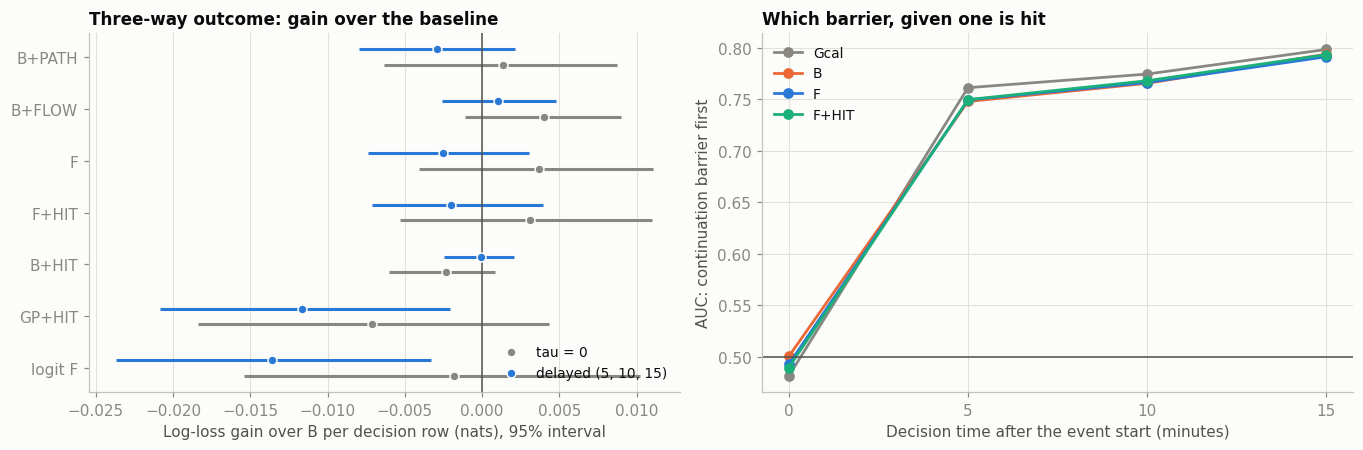

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
show = ["B+PATH", "B+FLOW", "F", "F+HIT", "B+HIT", "GP+HIT", "logit F"]
yy = np.arange(len(show))[::-1]
for off, (lab, col) in zip((-.15, .15), (("tau = 0", MUTED), ("delayed (5, 10, 15)", C["blue"]))):
    d = Q1[lab].loc[show]
    ax.hlines(yy + off, d["Δ lo"], d["Δ hi"], color=col, lw=2)
    ax.scatter(d["Δ vs B"], yy + off, color=col, s=34, zorder=3, label=lab, edgecolor=SURFACE)
ax.axvline(0, color=INK2, lw=1); ax.set_yticks(yy); ax.set_yticklabels(show); ax.grid(axis="y", visible=False)
ax.set_xlabel("Log-loss gain over B per decision row (nats), 95% interval"); ax.set_title("Three-way outcome: gain over the baseline"); ax.legend(loc="lower right")
ax = axes[1]
for k, col in (("Gcal", MUTED), ("B", C["orange"]), ("F", C["blue"]), ("F+HIT", C["aqua"])):
    ax.plot(BYTAU.index, BYTAU[k], marker="o", color=col, label=k)
ax.axhline(.5, color=INK2, lw=1); ax.set_xticks(TAUS); ax.set_xlabel("Decision time after the event start (minutes)"); ax.set_ylabel("AUC: continuation barrier first")
ax.set_title("Which barrier, given one is hit"); ax.legend()
fig.tight_layout(); plt.show()

**Interpretation.**

* **Direction at `τ = 0` is unpredictable.** Every model has a directional AUC between 0.48 and 0.51, and all are worse than the calibrated geometric baseline in directional log loss.
* **Direction after observation looks predictable, but it is geometry.** AUCs jump to 0.75–0.80 once the event is a few minutes old. The closed-form `G`, which knows nothing except where price is between the barriers and how much time is left, gets 0.776. No learned model beats it.
* **Learned models lose a little against geometry on direction** (−0.006 to −0.008 nats after observation, −0.013 to −0.018 at `τ = 0`). They spend capacity on noise that the geometric formula does not have to learn.
* **On the three-way outcome, nothing beats `B`.** Path, flow, the full set, and the attainment input all stay within ±0.004 nats of `B`, with intervals including zero. `GP+HIT`, which replaces volatility features with the attainment forecast, is clearly worse (−0.012): the forecast does not summarise them.
* **The logit check agrees.** The multinomial logit is worse than LightGBM on both sets, and `F` is no better than `B` there either.
* **Where the models do help is attainment.** Hit AUC rises from 0.62 (geometry) to about 0.68 on delayed decisions, and from 0.50 to about 0.65 at `τ = 0`. This repeats every earlier notebook: volatility and activity are forecastable.

### 9.2 Does observation add directional information, and is it more than the placebo?

The test is whether `F`'s directional gain over the calibrated geometric baseline is larger after observation than at the event start. The placebo refits `F` with path and flow columns permuted, so its gain is what flexibility alone buys.

In [14]:
md0, md1 = IMMED & res, DELAYED & res
g0 = boot_ratio(np.where(md0, LLD["Gcal"] - LLD["F"], 0), md0.astype(float), day)
g1 = boot_ratio(np.where(md1, LLD["Gcal"] - LLD["F"], 0), md1.astype(float), day)
print(f"Directional gain of F over Gcal: tau = 0 {np.nanmean(LLD['Gcal'][md0] - LLD['F'][md0]):+.4f} {np.round(ci(g0), 4)}; delayed {np.nanmean(LLD['Gcal'][md1] - LLD['F'][md1]):+.4f} {np.round(ci(g1), 4)}; difference delayed minus immediate {np.nanmean(LLD['Gcal'][md1] - LLD['F'][md1]) - np.nanmean(LLD['Gcal'][md0] - LLD['F'][md0]):+.4f} {np.round(ci(g1 - g0), 4)}.")

# Placebo distribution for the three-way gain of F over B on delayed rows.
pl_gain = []
for rep in range(N_PERM):
    P_ = np.vstack([r["mc"] for r in sorted([p for p in PLAC if p["rep"] == rep], key=lambda r: r["block"])])
    llp = np.where(nonamb, mll(P_, np.where(nonamb, y_all, 0)), np.nan)
    pl_gain.append(np.nanmean(LL["B"][DELAYED & nonamb] - llp[DELAYED & nonamb]))
pl_gain = np.array(pl_gain)
real_gain = Q1["delayed (5, 10, 15)"].loc["F", "Δ vs B"]
print(f"Three-way gain of F over B on delayed rows: {real_gain:+.4f}. Placebo (path and flow permuted, {N_PERM} draws): mean {pl_gain.mean():+.4f}, max {pl_gain.max():+.4f}. Real above all placebo draws: {bool(real_gain > pl_gain.max())}.")

# Stability by block.
rows = []
for b in range(len(BLOCKS)):
    m = (T["block"].to_numpy() == b)
    rows.append({"block": f"{BLOCKS[b][0]:%b}–{(BLOCKS[b][1] - pd.Timedelta(days=1)):%b %Y}", "events": T.loc[m, "event"].nunique(),
                 "Δ F vs B, delayed": np.nanmean((LL["B"] - LL["F"])[m & DELAYED & nonamb]), "Δ F+HIT vs F, delayed": np.nanmean((LL["F"] - LL["F+HIT"])[m & DELAYED & nonamb]),
                 "dir. Δ F vs Gcal, tau 0": np.nanmean((LLD["Gcal"] - LLD["F"])[m & IMMED & res]), "dir. Δ F vs Gcal, delayed": np.nanmean((LLD["Gcal"] - LLD["F"])[m & DELAYED & res]),
                 "dir. AUC F, delayed": auc_nb(PDIR["F"][m & DELAYED & res], (y_all[m & DELAYED & res] == CONT).astype(np.int64))})
STAB1 = pd.DataFrame(rows).set_index("block"); display(STAB1.round(4))

Directional gain of F over Gcal: tau = 0 -0.0176 [-0.0271 -0.0076]; delayed -0.0070 [-0.0158  0.001 ]; difference delayed minus immediate +0.0106 [0.0018 0.0192].
Three-way gain of F over B on delayed rows: -0.0025. Placebo (path and flow permuted, 12 draws): mean -0.0002, max +0.0035. Real above all placebo draws: False.


,events,"Δ F vs B, delayed","Δ F+HIT vs F, delayed","dir. Δ F vs Gcal, tau 0","dir. Δ F vs Gcal, delayed","dir. AUC F, delayed"
block,,,,,,
Feb–Apr 2026,652,0.0031,-0.0001,-0.0111,-0.0109,0.7892
May–Jul 2026,651,-0.0022,0.0012,-0.0219,-0.0065,0.7502
Aug–Oct 2026,743,-0.0077,0.0004,-0.0194,-0.0044,0.7639


**Interpretation.**

* **The pre-specified Q1b criterion is met, but only technically.** The difference between delayed and immediate directional gain is +0.011 [+0.002, +0.019]. The gain itself is −0.018 at `τ = 0` and −0.007 after observation. Observation reduces how much the model **loses** against geometry; it never produces a gain. I report the criterion as met and the conclusion as negative, because the criterion did not anticipate both values being below zero.
* **Path and flow information behave like noise.** The real `F` model's three-way gain over `B` (−0.0025) sits inside the placebo distribution (mean −0.0002, maximum +0.0035), where path and flow columns were permuted.
* **Blocks agree.** `F` beats `B` in only 1 of 3 blocks, and `F` loses to geometry on direction in all 3. The attainment forecast is neutral in all 3.

### 9.3 Calibration

Reliability of the continuation-first probability on delayed rows, in deciles of the prediction. A well-calibrated model lies on the diagonal. `ECE` is the mean absolute gap, weighted by decile size.

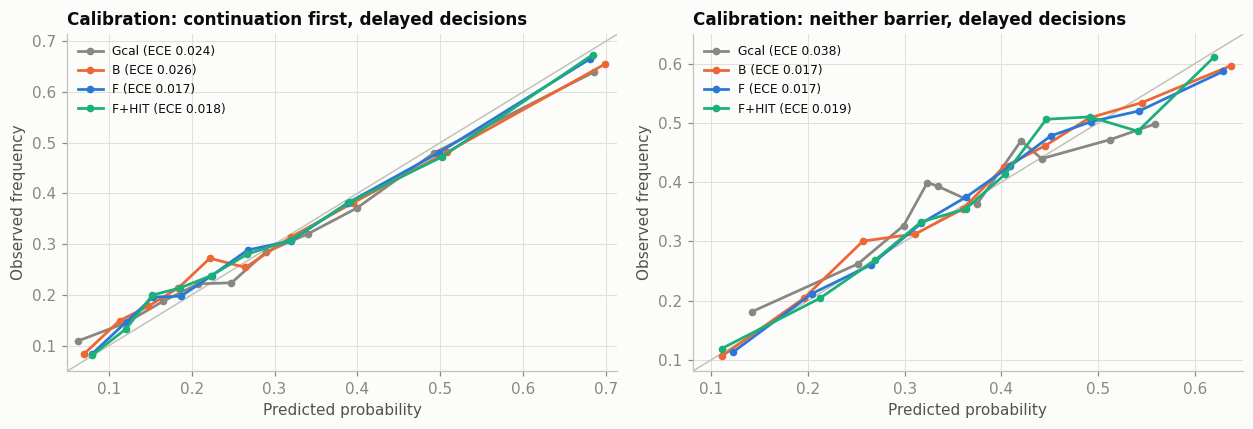

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
CALT = {}
for ax, cls_, lab in ((axes[0], CONT, "continuation first"), (axes[1], NEITHER, "neither barrier")):
    m = DELAYED & nonamb
    ax.plot([0, 1], [0, 1], color=AXIS, lw=1)
    for k, col in (("Gcal", MUTED), ("B", C["orange"]), ("F", C["blue"]), ("F+HIT", C["aqua"])):
        p = PROB[k][m, cls_]; yv = (y_all[m] == cls_).astype(float)
        bins = pd.qcut(p, 10, labels=False, duplicates="drop")
        g_ = pd.DataFrame({"p": p, "y": yv, "b": bins}).groupby("b").mean()
        cnt = pd.Series(bins).value_counts().sort_index().to_numpy()
        CALT[(lab, k)] = float(np.sum(np.abs(g_["p"] - g_["y"]).to_numpy() * cnt) / cnt.sum())
        ax.plot(g_["p"], g_["y"], marker="o", ms=4, color=col, label=f"{k} (ECE {CALT[(lab, k)]:.3f})")
    lo_ = min(g_["p"].min(), g_["y"].min()) - .03; hi_ = max(g_["p"].max(), g_["y"].max()) + .03
    ax.set_xlim(max(lo_, 0), min(hi_, 1)); ax.set_ylim(max(lo_, 0), min(hi_, 1))
    ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed frequency"); ax.set_title(f"Calibration: {lab}, delayed decisions"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

**Calibration.** On the continuation-first probability, all models are close to the diagonal (ECE 0.017 to 0.026). On "neither barrier", the learned models are clearly better calibrated than geometry (0.017 against 0.038). Geometry assumes the pre-event volatility, but volatility after an impulse is different. Good calibration here is about **whether** something happens, not **which way**.

## 10. Question 2: better entries, or only higher win rates? `EXPLORATORY`

### 10.1 Policies and controls

Every number here is **executable gross** under the base execution (1 s latency, worst price in the second), from the actual entry price to the anchored barrier or expiry. Thresholds come from training out-of-fold scores; the test block never moves them.

**Per trade** is the average over trades taken. **Per event** divides the total by **all** test events, including those never traded, those resolved before a delayed decision, and those cancelled between decision and entry. The second is the honest measure of what the policy extracts from the original opportunities.

In [16]:
EV_E = EV["e"].to_numpy()

def thresholds(run, name):
    # Sequential: smallest |score| threshold that trades RETENTION of training events. Fixed tau: same share of events at that tau.
    rows = run["rows_tr"]; s = np.abs(run["oof"][name]); ev = PANEL["event"].to_numpy()[rows]; tau = PANEL["tau"].to_numpy()[rows]
    ok = np.isfinite(s); n_ev = np.unique(ev).size
    cand = np.quantile(s[ok], np.linspace(0, .999, 400))
    best = cand[-1]
    for th in cand:
        if np.unique(ev[ok & (s >= th)]).size <= RETENTION * n_ev:
            best = th; break
    fixed = {}
    for t_ in TAUS:
        st = np.sort(s[ok & (tau == t_)])[::-1]
        k_ = int(min(RETENTION * n_ev, st.size)) - 1
        fixed[t_] = st[k_] if k_ >= 0 else np.inf
    return best, fixed

TH = {name: [thresholds(r, name) for r in MAINR] for name in TRADE_SETS}

def select(name, policy, score=None):
    # Returns test-panel row indices chosen, one per event at most, and the side in the event frame (+1 continuation).
    s = SCORE[name] if score is None else score
    th_seq = np.array([TH[name][b][0] for b in T["block"]]) if name in TH else None
    tau = T["tau"].to_numpy(); ev = T["event"].to_numpy()
    if policy == "SEQUENTIAL":
        ok = np.abs(s) >= th_seq
        o = np.lexsort((tau, ev)); chosen = {}
        for i in o:
            if ok[i] and ev[i] not in chosen:
                chosen[ev[i]] = i
        idx = np.array(sorted(chosen.values()), int)
    else:
        t_ = int(policy.split()[-1])
        thr = np.array([TH[name][b][1][t_] for b in T["block"]])
        idx = np.flatnonzero((tau == t_) & (np.abs(s) >= thr))
    return idx, np.sign(s[idx]).astype(int)

def trades(idx, side_frame, v=0):
    # Executable outcome of the chosen rows. side_frame is +1 continuation, -1 reversal; converted to long or short.
    ev = T["event"].to_numpy()[idx]; j = np.array([TAUS.index(int(t)) for t in T["tau"].to_numpy()[idx]], int)
    real = side_frame * EV_E[ev]; k = np.where(real > 0, 0, 1)
    g = GROSS[ev, j, k, v]; st = STATUS[ev, j, k, v]
    fund = real * EV["fund_long_bps"].to_numpy()[ev]
    return pd.DataFrame({"row": idx, "event": ev, "tau": T["tau"].to_numpy()[idx], "side": side_frame, "gross": g, "status": st, "fund": fund, "dayi": T["dayi"].to_numpy()[idx], "month": EV["month"].to_numpy()[ev]})

N_TEST_EV = T["event"].nunique()
def summ(tr, label):
    t = tr[tr["status"] == ST_TRADE]
    return {"policy": label, "chosen": len(tr), "traded": len(t), "events traded %": 100 * len(t) / N_TEST_EV, "cancelled": int((tr["status"] == ST_CANCEL).sum()),
            "gross / trade": t["gross"].mean(), "gross / event": t["gross"].sum() / N_TEST_EV, "win rate": (t["gross"] > 0).mean(), "mean |gross|": t["gross"].abs().mean(),
            "net / trade @10": (t["gross"] - 10 - t["fund"]).mean()}

def boot_trade_mean(tr):
    t = tr[tr["status"] == ST_TRADE]
    return boot_ratio(t["gross"].to_numpy(), np.ones(len(t)), t["dayi"].to_numpy())

rng_c = np.random.default_rng(SEED + 99)
POLICIES = ["IMMEDIATE", "FIXED 5", "FIXED 10", "FIXED 15", "SEQUENTIAL"]
pol_rows, BOOTS, CTRL = [], {}, {}
for pol in POLICIES:
    p_ = "FIXED 0" if pol == "IMMEDIATE" else pol
    for name in TRADE_SETS:
        idx, sd = select(name, p_)
        tr = trades(idx, sd); pol_rows.append({**summ(tr, f"{pol} | {name}"), "pol": pol, "model": name}); BOOTS[(pol, name)] = boot_trade_mean(tr)
    # Controls at the rows chosen by F.
    idx, sd = select("F", p_)
    tl, ts = trades(idx, np.ones(idx.size, int)), trades(idx, -np.ones(idx.size, int))
    ok_ = (tl["status"] == ST_TRADE).to_numpy()
    rs = pd.DataFrame({"gross": .5 * (tl["gross"] + ts["gross"]), "status": tl["status"], "fund": 0.0, "dayi": tl["dayi"]})       # random side: exact expectation
    pol_rows.append({**summ(rs, f"{pol} | F rows, random side"), "win rate": np.nan, "mean |gross|": np.nan, "pol": pol, "model": "random side"}); BOOTS[(pol, "random side")] = boot_trade_mean(rs)   # an exact expectation, so win rate and |gross| do not apply
    pol_rows.append({**summ(tl, f"{pol} | F rows, always continuation"), "pol": pol, "model": "continuation"})
    pol_rows.append({**summ(ts, f"{pol} | F rows, always reversal"), "pol": pol, "model": "reversal"})
    near = np.where(T["a"].to_numpy()[idx] <= T["b"].to_numpy()[idx], 1, -1)
    pol_rows.append({**summ(trades(idx, near), f"{pol} | F rows, nearer barrier"), "pol": pol, "model": "nearer barrier"})
    # Random selection: F's side on random rows with the same month and decision time as each chosen row.
    tau_all = T["tau"].to_numpy(); mon = EV["month"].to_numpy()[T["event"].to_numpy()]
    pools = {}
    draws = []
    for rep in range(CTRL_REPS):
        pick = []
        for i in idx:
            key = (mon[i], tau_all[i])
            if key not in pools:
                pools[key] = np.flatnonzero((mon == mon[i]) & (tau_all == tau_all[i]))
            pick.append(rng_c.choice(pools[key]))
        pick = np.array(pick, int)
        t_ = trades(pick, np.sign(SCORE["F"][pick]).astype(int)); t_ = t_[t_["status"] == ST_TRADE]
        draws.append(t_["gross"].mean())
    CTRL[pol] = np.array(draws)
    f_mean = summ(trades(idx, sd), "")["gross / trade"]
    pol_rows.append({"policy": f"{pol} | F side, random rows", "pol": pol, "model": "random selection", "gross / trade": np.mean(draws), "pct of F vs random selection": float(np.mean(np.array(draws) < f_mean))})
POL = pd.DataFrame(pol_rows).set_index("policy")
display(POL.drop(columns=["pol", "model"]).round({"events traded %": 1, "gross / trade": 2, "gross / event": 2, "win rate": 3, "mean |gross|": 1, "net / trade @10": 2, "pct of F vs random selection": 3}))

rows = []
for pol in POLICIES:
    f = BOOTS[(pol, "F")]
    for other in ("B", "F+HIT", "random side"):
        d = f - BOOTS[(pol, other)]
        rows.append({"policy": pol, "comparison": f"F minus {other}", "difference (bps / trade)": np.nanmean(f) - np.nanmean(BOOTS[(pol, other)]), "lo": ci(d)[0], "hi": ci(d)[1]})
    rows.append({"policy": pol, "comparison": "F gross per trade", "difference (bps / trade)": np.nanmean(f), "lo": ci(f)[0], "hi": ci(f)[1]})
PAIR = pd.DataFrame(rows).set_index(["policy", "comparison"])
display(PAIR.round(2))

,chosen,traded,events traded %,cancelled,gross / trade,gross / event,win rate,mean |gross|,net / trade @10,pct of F vs random selection
policy,,,,,,,,,,
IMMEDIATE | B,554.0,554.0,27.1,0.0,-0.27,-0.07,0.529,29.0,-10.27,NaN
IMMEDIATE | F,526.0,526.0,25.7,0.0,-2.98,-0.76,0.483,29.8,-12.98,NaN
IMMEDIATE | F+HIT,540.0,540.0,26.4,0.0,-3.27,-0.86,0.478,29.3,-13.28,NaN
"IMMEDIATE | F rows, random side",526.0,526.0,25.7,0.0,-1.63,-0.42,NaN,NaN,-11.63,NaN
"IMMEDIATE | F rows, always continuation",526.0,526.0,25.7,0.0,-3.93,-1.01,0.473,29.8,-13.93,NaN
"IMMEDIATE | F rows, always reversal",526.0,526.0,25.7,0.0,0.66,0.17,0.517,30.1,-9.33,NaN
"IMMEDIATE | F rows, nearer barrier",526.0,526.0,25.7,0.0,-5.37,-1.38,0.456,30.0,-15.37,NaN
"IMMEDIATE | F side, random rows",NaN,NaN,NaN,NaN,-0.93,NaN,NaN,NaN,NaN,0.075
FIXED 5 | B,503.0,503.0,24.6,0.0,-2.06,-0.51,0.481,24.8,-12.06,NaN


difference (bps / trade)    lo    hi
policy     comparison                                               
IMMEDIATE  F minus B                               -2.70 -5.33  0.12
           F minus F+HIT                            0.30 -1.36  1.91
           F minus random side                     -1.30 -4.20  1.55
           F gross per trade                       -2.93 -5.85 -0.07
FIXED 5    F minus B                                0.48 -2.75  3.51
           F minus F+HIT                            0.28 -1.23  1.89
           F minus random side                     -0.57 -3.17  1.89
           F gross per trade                       -1.61 -4.11  0.75
FIXED 10   F minus B                               -0.90 -3.88  1.92
           F minus F+HIT                            0.45 -0.76  1.70
           F minus random side                     -0.06 -2.61  2.62
           F gross per trade                       -1.02 -3.53  1.62
FIXED 15   F minus B                               -1.86 -4.61  0.61
           F minus F+HIT                           -0.09 -1.42  1.26
           F minus random side                     -0.73 -3.35  1.76
           F gross per trade                       -1.63 -4.22  0.88
SEQUENTIAL F minus B                               -4.58 -7.90 -1.23
           F minus F+HIT                           -0.44 -1.92  0.96
           F minus random side                     -3.00 -5.79 -0.20
           F gross per trade                       -4.51 -7.36 -1.78

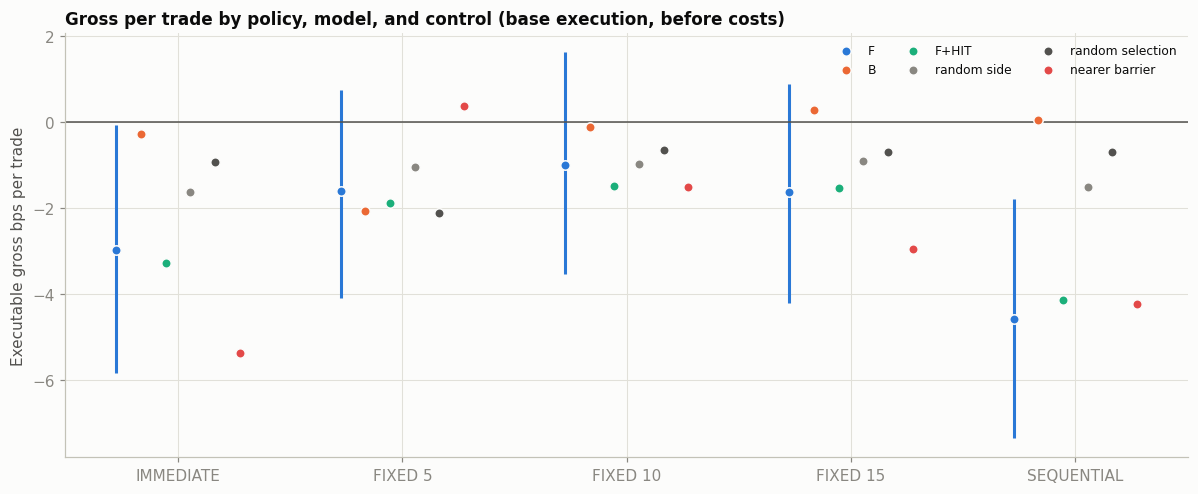

In [17]:
fig, ax = plt.subplots(figsize=(11, 4.6))
mods = [("F", C["blue"]), ("B", C["orange"]), ("F+HIT", C["aqua"]), ("random side", MUTED), ("random selection", INK2), ("nearer barrier", C["red"])]
x = np.arange(len(POLICIES))
for k_, (m_, col) in enumerate(mods):
    vals = [POL[(POL["pol"] == p) & (POL["model"] == m_)]["gross / trade"].iloc[0] for p in POLICIES]
    ax.scatter(x + (k_ - 2.5) * .11, vals, color=col, s=38, label=m_, zorder=3, edgecolor=SURFACE)
    if m_ == "F":
        lo_ = [ci(BOOTS[(p, "F")])[0] for p in POLICIES]; hi_ = [ci(BOOTS[(p, "F")])[1] for p in POLICIES]
        ax.vlines(x + (k_ - 2.5) * .11, lo_, hi_, color=col, lw=2)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(x); ax.set_xticklabels(POLICIES); ax.set_ylabel("Executable gross bps per trade"); ax.legend(ncol=3, fontsize=8)
ax.set_title("Gross per trade by policy, model, and control (base execution, before costs)")
fig.tight_layout(); plt.show()

**Interpretation.**

* **No model-based policy produces a positive gross that is distinguishable from zero.** The best point estimate is +0.3 bps (`B`, fixed at 15 minutes).
* **The full model is consistently worse than the simpler baseline.** In the sequential policy it loses 4.6 bps per trade, 4.6 bps below `B` [−7.9, −1.2], 3.0 bps below a random side on the same rows [−5.8, −0.2], and below 99.5% of random row selections with the same side rule.
* **Why the full model loses.** It selects mostly continuation trades (421 of 467), on rows where trading the opposite way would have earned +1.6 bps. Path and flow features lead it to continuation exactly when the impulse later reverses. Section 13 shows that the continuation lean was present in training too, so this is not a sign error. It is a learned pattern that did not hold out of sample.
* **The nearer-barrier rule shows the geometric trap.** It wins 55–59% of delayed trades and still earns between −3.0 and +0.4 bps. A high probability of reaching the nearer barrier is compensated by a smaller payoff, exactly as the martingale argument predicts.
* **Per original event**, every policy extracts between −1.4 and +0.2 bps, so even the best case is negligible against the opportunity set.

### 10.2 Does a higher score mean a better trade?

On delayed rows, each decile of the absolute expected-return score, traded in the model's direction. Win rate and gross are shown side by side, because a rising win rate with a flat gross means the model is only picking trades toward the nearer barrier.

,model,gross,win,toward_nearer,n
decile,,,,,
0,B,-0.590,0.503,0.499,495
1,B,2.815,0.548,0.500,496
2,B,-1.329,0.498,0.484,494
3,B,-0.072,0.496,0.506,496
4,B,-2.654,0.482,0.506,496
5,B,-1.532,0.471,0.459,495
6,B,-0.265,0.531,0.493,495
7,B,2.049,0.541,0.472,492
8,B,-0.211,0.512,0.433,496


Rank correlation between expected-return score and the frictionless oriented return, delayed rows: {'B': np.float64(0.0167), 'B+PATH': np.float64(-0.0131), 'B+FLOW': np.float64(0.0067), 'F': np.float64(-0.0056), 'F+HIT': np.float64(-0.0035)}


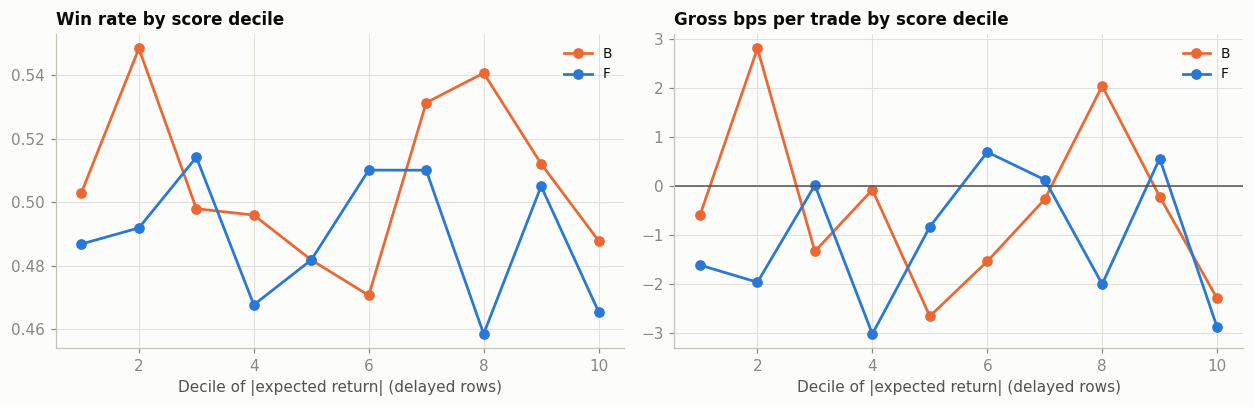

In [18]:
m = DELAYED
dec_rows = []
for name in ("B", "F"):
    s = SCORE[name][m]; sd = np.sign(s).astype(int); idx = np.flatnonzero(m)
    tr = trades(idx, sd); ok_ = (tr["status"] == ST_TRADE).to_numpy()
    q = pd.qcut(np.abs(s), 10, labels=False, duplicates="drop")
    near = (np.where(T["a"].to_numpy()[idx] <= T["b"].to_numpy()[idx], 1, -1) == sd)
    d = pd.DataFrame({"decile": q, "gross": tr["gross"].to_numpy(), "win": tr["gross"].to_numpy() > 0, "toward nearer": near, "ok": ok_})
    d = d[d["ok"]].groupby("decile").agg(gross=("gross", "mean"), win=("win", "mean"), toward_nearer=("toward nearer", "mean"), n=("gross", "size"))
    d.insert(0, "model", name); dec_rows.append(d)
DEC = pd.concat(dec_rows)
display(DEC.round(3))
ic = {name: stats.spearmanr(SCORE[name][m], T["y_ret"].to_numpy()[m])[0] for name in ("B", "B+PATH", "B+FLOW", "F", "F+HIT")}
print("Rank correlation between expected-return score and the frictionless oriented return, delayed rows:", {k: round(v, 4) for k, v in ic.items()})
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for name, col in (("B", C["orange"]), ("F", C["blue"])):
    d = DEC[DEC["model"] == name]
    axes[0].plot(d.index + 1, d["win"], marker="o", color=col, label=name); axes[1].plot(d.index + 1, d["gross"], marker="o", color=col, label=name)
axes[0].set_title("Win rate by score decile"); axes[1].set_title("Gross bps per trade by score decile"); axes[1].axhline(0, color=INK2, lw=1)
for ax in axes:
    ax.set_xlabel("Decile of |expected return| (delayed rows)"); ax.legend()
fig.tight_layout(); plt.show()

**Interpretation.** There is no gradient. Neither the win rate nor the gross rises with the absolute expected-return score, for either model. The rank correlation between score and realised frictionless return is between −0.013 and +0.017 for every feature set. Higher-scoring `F` trades lean **away** from the nearer barrier (37% toward it in the top decile), so the model is not just exploiting geometry. It simply has no directional skill.

### 10.3 How much room is left after a delayed entry?

For each decision time on test events: how many events are still available, how far the anchored barriers are from the entry, and what a trade in each fixed direction earns after honest execution. **Execution drag** is the frictionless continuation return from the decision price minus the executable continuation gross: what latency and the worst price in the second cost.

In [19]:
rows = []
for j, tau in enumerate(TAUS):
    m = T["tau"].to_numpy() == tau
    ev = T["event"].to_numpy()[m]
    ev_all = np.unique(T["event"].to_numpy())
    st_l = STATUS[ev, j, 0, 0]
    lc = trades(np.flatnonzero(m), np.ones(m.sum(), int)); lr = trades(np.flatnonzero(m), -np.ones(m.sum(), int))
    okc = lc["status"] == ST_TRADE
    fric_bps = 1e4 * T["y_ret"].to_numpy()[m] * EV["w"].to_numpy()[ev]
    rows.append({"tau": tau, "surviving %": 100 * m.sum() / ev_all.size, "cancelled before entry %": 100 * np.mean(st_l == ST_CANCEL),
                 "to cont. barrier (bps)": 1e4 * np.median(T["a"].to_numpy()[m]), "to rev. barrier (bps)": 1e4 * np.median(T["b"].to_numpy()[m]),
                 "cont. first %": 100 * np.mean(T["cls"].to_numpy()[m] == CONT), "rev. first %": 100 * np.mean(T["cls"].to_numpy()[m] == REV),
                 "frictionless cont. return (bps)": fric_bps.mean(), "exec. continuation gross": lc.loc[okc, "gross"].mean(), "exec. reversal gross": lr.loc[lr["status"] == ST_TRADE, "gross"].mean(),
                 "mean |exec. gross|": lc.loc[okc, "gross"].abs().mean(), "execution drag (bps)": fric_bps[okc.to_numpy()].mean() - lc.loc[okc, "gross"].mean()})
ROOM = pd.DataFrame(rows).set_index("tau"); display(ROOM.round(2))

,surviving %,cancelled before entry %,to cont. barrier (bps),to rev. barrier (bps),cont. first %,rev. first %,frictionless cont. return (bps),exec. continuation gross,exec. reversal gross,mean |exec. gross|,execution drag (bps)
tau,,,,,,,,,,,
0,100.00,0.00,31.82,31.82,36.66,32.60,0.40,-0.64,-2.20,29.23,1.04
5,89.83,0.00,32.71,28.86,31.99,33.79,0.33,-0.50,-1.55,24.97,0.79
10,80.50,0.18,31.97,28.24,29.75,32.06,0.45,-0.30,-1.51,22.94,0.74
15,72.09,0.20,32.19,27.48,27.19,30.17,0.35,-0.29,-1.36,21.50,0.64


**Is there enough movement after a delayed entry?**

* **In size, yes.** A surviving trade still moves 21–29 bps in absolute terms between entry and exit. The continuation barrier stays about 32 bps away, and the reversal barrier 27–29 bps, so a correct side choice would comfortably pay a 10 bps round trip.
* **Honest execution costs little here:** 0.6 to 1.0 bps of drag from 1 s latency and the worst price in the entry second. The "slow" variant with 5 s latency changes gross by less than 0.2 bps (section 11), so this is not a latency problem.
* **The problem is direction.** Fixed continuation and fixed reversal both earn between −2.2 and −0.3 bps at every decision time. The room exists, but no feature here says which side of it to take.

## 11. Question 3: under which costs and execution, if any? `EXPLORATORY`

Net per trade for the main policies, under the three execution variants and five round-trip cost levels. Funding is charged when a settlement falls inside the event window. **Break-even** is the round-trip cost at which net per trade is zero.

trades  gross / trade  net @0  net @2  net @4  net @7  net @10  break-even cost
policy     model execution                                                                                                
IMMEDIATE  B     base: 1 s, worst price       554          -0.27   -0.27   -2.27   -4.27   -7.27   -10.27            -0.27
                 neutral: 1 s, last price     554           0.98    0.98   -1.02   -3.02   -6.02    -9.02             0.98
                 slow: 5 s, worst price       554          -0.25   -0.25   -2.25   -4.25   -7.25   -10.25            -0.25
           F     base: 1 s, worst price       526          -2.98   -2.98   -4.98   -6.98   -9.98   -12.98            -2.98
                 neutral: 1 s, last price     526          -1.56   -1.56   -3.56   -5.56   -8.56   -11.56            -1.56
                 slow: 5 s, worst price       525          -2.89   -2.89   -4.89   -6.89   -9.89   -12.89            -2.89
           F+HIT base: 1 s, worst price       540          -3.27   -3.28   -5.28   -7.28  -10.28   -13.28            -3.28
                 neutral: 1 s, last price     540          -1.92   -1.92   -3.92   -5.92   -8.92   -11.92            -1.92
                 slow: 5 s, worst price       539          -3.26   -3.26   -5.26   -7.26  -10.26   -13.26            -3.26
FIXED 5    B     base: 1 s, worst price       503          -2.06   -2.06   -4.06   -6.06   -9.06   -12.06            -2.06
                 neutral: 1 s, last price     503          -0.98   -0.98   -2.98   -4.98   -7.98   -10.98            -0.98
                 slow: 5 s, worst price       503          -2.12   -2.12   -4.12   -6.12   -9.12   -12.12            -2.12
           F     base: 1 s, worst price       499          -1.61   -1.61   -3.61   -5.61   -8.61   -11.61            -1.61
                 neutral: 1 s, last price     499          -0.58   -0.58   -2.58   -4.58   -7.58   -10.58            -0.58
                 slow: 5 s, worst price       497          -1.66   -1.66   -3.66   -5.66   -8.66   -11.66            -1.66
           F+HIT base: 1 s, worst price       484          -1.89   -1.89   -3.89   -5.89   -8.89   -11.89            -1.89
                 neutral: 1 s, last price     484          -0.88   -0.88   -2.88   -4.88   -7.88   -10.88            -0.88
                 slow: 5 s, worst price       481          -1.96   -1.96   -3.96   -5.96   -8.96   -11.96            -1.96
FIXED 10   B     base: 1 s, worst price       523          -0.10   -0.11   -2.11   -4.11   -7.11   -10.11            -0.11
                 neutral: 1 s, last price     523           0.92    0.92   -1.08   -3.08   -6.08    -9.08             0.92
                 slow: 5 s, worst price       523           0.06    0.06   -1.94   -3.94   -6.94    -9.94             0.06
           F     base: 1 s, worst price       521          -1.01   -1.00   -3.00   -5.00   -8.00   -11.00            -1.00
                 neutral: 1 s, last price     521          -0.07   -0.06   -2.06   -4.06   -7.06   -10.06            -0.06
                 slow: 5 s, worst price       521          -0.86   -0.85   -2.85   -4.85   -7.85   -10.85            -0.85
           F+HIT base: 1 s, worst price       511          -1.48   -1.47   -3.47   -5.47   -8.47   -11.47            -1.47
                 neutral: 1 s, last price     511          -0.49   -0.48   -2.48   -4.48   -7.48   -10.48            -0.48
                 slow: 5 s, worst price       511          -1.33   -1.32   -3.32   -5.32   -8.32   -11.32            -1.32
FIXED 15   B     base: 1 s, worst price       530           0.28    0.30   -1.70   -3.70   -6.70    -9.70             0.30
                 neutral: 1 s, last price     530           1.09    1.10   -0.90   -2.90   -5.90    -8.90             1.10
                 slow: 5 s, worst price       528           0.42    0.43   -1.57   -3.57   -6.57    -9.57             0.43
           F     base: 1 s, worst price       527          -1.62   -1.62   -3.62   -5.62   -8.62   -11.62  

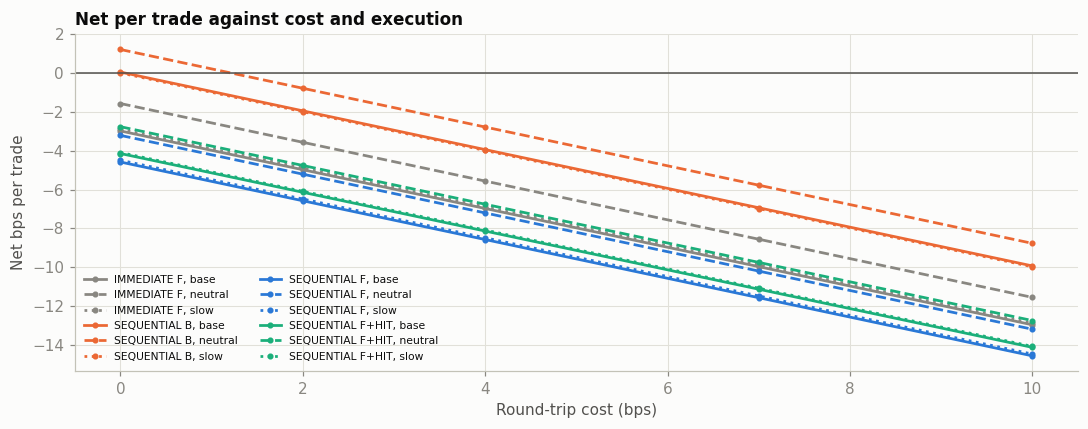

In [20]:
rows = []
for pol in POLICIES:
    p_ = "FIXED 0" if pol == "IMMEDIATE" else pol
    for name in ("B", "F", "F+HIT"):
        idx, sd = select(name, p_)
        for v, vn in enumerate(V_NAMES):
            t = trades(idx, sd, v); t = t[t["status"] == ST_TRADE]
            g = t["gross"].mean(); f = t["fund"].mean()
            rows.append({"policy": pol, "model": name, "execution": vn, "trades": len(t), "gross / trade": g, **{f"net @{c}": g - c - f for c in COSTS}, "break-even cost": g - f})
COSTT = pd.DataFrame(rows).set_index(["policy", "model", "execution"])
display(COSTT.round(2))
fig, ax = plt.subplots(figsize=(10, 4))
for (pol, name), col in ((("IMMEDIATE", "F"), MUTED), (("SEQUENTIAL", "B"), C["orange"]), (("SEQUENTIAL", "F"), C["blue"]), (("SEQUENTIAL", "F+HIT"), C["aqua"])):
    for v, ls in zip(range(3), ("-", "--", ":")):
        r_ = COSTT.loc[(pol, name, V_NAMES[v])]
        ax.plot(COSTS, [r_[f"net @{c}"] for c in COSTS], color=col, ls=ls, marker="o", ms=3, label=f"{pol} {name}, {V_NAMES[v].split(':')[0]}")
ax.axhline(0, color=INK2, lw=1); ax.set_xlabel("Round-trip cost (bps)"); ax.set_ylabel("Net bps per trade"); ax.set_title("Net per trade against cost and execution")
ax.legend(fontsize=7, ncol=2); fig.tight_layout(); plt.show()

**Interpretation.**

* **The full model is negative at zero cost** under every execution variant and every policy.
* **The baseline `B` is close to zero gross:** +0.9 to +1.2 bps with neutral execution, the most favourable variant. That is less than any realistic round-trip cost, and its interval includes zero.
* **Execution changes about 1 bp:** neutral execution adds 0.8–1.4 bps over the base, and slow execution is the same as base.
* **No cost level makes any model-based policy reliably positive.** Break-even costs are all at or below about +1.2 bps.

## 12. Stability across periods `EXPLORATORY`

In [21]:
rows = []
for b in range(len(BLOCKS)):
    lab = f"{BLOCKS[b][0]:%b}–{(BLOCKS[b][1] - pd.Timedelta(days=1)):%b %Y}"
    for pol in ("IMMEDIATE", "SEQUENTIAL"):
        p_ = "FIXED 0" if pol == "IMMEDIATE" else pol
        r_ = {"block": lab, "policy": pol}
        for name in ("B", "F", "F+HIT"):
            idx, sd = select(name, p_)
            t = trades(idx, sd); t = t[(t["status"] == ST_TRADE) & (T["block"].to_numpy()[t["row"]] == b)]
            r_[f"{name} gross/trade"] = t["gross"].mean(); r_[f"{name} trades"] = len(t)
        idx, sd = select("F", p_)
        tl, ts = trades(idx, np.ones(idx.size, int)), trades(idx, -np.ones(idx.size, int))
        mb = (T["block"].to_numpy()[idx] == b) & (tl["status"] == ST_TRADE).to_numpy()
        r_["random side gross/trade"] = (.5 * (tl["gross"] + ts["gross"]))[mb].mean()
        rows.append(r_)
STAB = pd.DataFrame(rows).set_index(["block", "policy"]); display(STAB.round(2))
idx, sd = select("F", "SEQUENTIAL"); t = trades(idx, sd); t = t[t["status"] == ST_TRADE]
MON = t.groupby("month")["gross"].agg(["mean", "size"])
print(f"SEQUENTIAL F, monthly gross per trade: positive in {(MON['mean'] > 0).sum()} of {len(MON)} months.")
display(MON.T.round(1))

B gross/trade  B trades  F gross/trade  F trades  F+HIT gross/trade  F+HIT trades  random side gross/trade
block        policy                                                                                                                
Feb–Apr 2026 IMMEDIATE           -2.65       159          -5.54       130              -3.90           127                    -2.55
             SEQUENTIAL          -1.99       132          -8.46       111              -5.75           108                    -2.43
May–Jul 2026 IMMEDIATE            0.58       193          -1.95       193              -4.15           202                    -1.37
             SEQUENTIAL           1.65       166          -2.79       162              -3.55           174                    -1.38
Aug–Oct 2026 IMMEDIATE            0.79       202          -2.30       203              -2.05           211                    -1.30
             SEQUENTIAL           0.09       181          -3.85       194              -3.78           197                    -1.11

SEQUENTIAL F, monthly gross per trade: positive in 1 of 9 months.


month,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
mean,-19.0,-8.8,5.0,-1.2,-3.8,-2.8,-5.1,-5.4,-1.5
size,41.0,37.0,33.0,39.0,57.0,66.0,60.0,61.0,73.0


**Stability.** The full model is below the baseline in every block for both policies, and the sequential full-model policy is positive in only 1 of 9 months. The baseline varies around zero (−2.7 to +1.7 bps). Nothing suggests a hidden period of usefulness.

## 13. Diagnostics `POST-HOC`

Two checks added **after** seeing the results above. They explain results; they do not replace the pre-specified tests.

1. **Direction tilt.** Why is the full model worse than the baseline in the sequential policy? If the models learned a continuation or reversal lean from training that did not hold in test, the side composition will show it.
2. **Attainment gate.** The brief asks whether direction becomes useful **when combined with** an attainment forecast. The design tested the forecast as a model input. Here it is used as a filter instead: trade only rows where the out-of-sample attainment forecast is above its training median. One variant only, fixed before looking at its result.

In [22]:
rows = []
for b, r in enumerate(MAINR):
    rtr = r["rows_tr"]; t0_tr = PANEL["tau"].to_numpy()[rtr] == 0
    m_te = (T["block"].to_numpy() == b)
    rows.append({"block": f"{BLOCKS[b][0]:%b}–{(BLOCKS[b][1] - pd.Timedelta(days=1)):%b %Y}",
                 "train: mean oriented return, tau 0": PANEL["y_ret"].to_numpy()[rtr][t0_tr].mean(), "test: mean oriented return, tau 0": T["y_ret"].to_numpy()[m_te & IMMED].mean(),
                 "train OOF: F continuation share": np.mean(r["oof"]["F"] > 0), "test: F continuation share": np.mean(SCORE["F"][m_te] > 0),
                 "train OOF: B continuation share": np.mean(r["oof"]["B"] > 0), "test: B continuation share": np.mean(SCORE["B"][m_te] > 0)})
TILT = pd.DataFrame(rows).set_index("block"); display(TILT.round(3))
idx, sd = select("F", "SEQUENTIAL"); tf = trades(idx, sd); tf = tf[tf["status"] == ST_TRADE]
idx, sd = select("B", "SEQUENTIAL"); tb = trades(idx, sd); tb = tb[tb["status"] == ST_TRADE]
print("SEQUENTIAL policy, gross per trade by chosen side (event frame):")
display(pd.DataFrame({"F": tf.groupby("side")["gross"].agg(["mean", "size"]).stack(), "B": tb.groupby("side")["gross"].agg(["mean", "size"]).stack()}).round(2))

print("SEQUENTIAL policy, gross per trade by decision time of entry:")
display(pd.DataFrame({"F": tf.groupby("tau")["gross"].agg(["mean", "size"]).stack(), "B": tb.groupby("tau")["gross"].agg(["mean", "size"]).stack()}).round(2))

# Attainment gate.
med = np.array([np.nanmedian(r["hit_tr"]["hit_F"]) for r in MAINR])[T["block"].to_numpy()]
gate = HIT_TE >= med
rows = []
for lab, mask in (("delayed rows, hit forecast >= training median", DELAYED & gate), ("delayed rows, hit forecast below", DELAYED & ~gate), ("all delayed rows", DELAYED)):
    idx = np.flatnonzero(mask)
    for name in ("B", "F", "F+HIT"):
        t = trades(idx, np.sign(SCORE[name][idx]).astype(int)); t = t[t["status"] == ST_TRADE]
        bt = boot_ratio(t["gross"].to_numpy(), np.ones(len(t)), t["dayi"].to_numpy())
        rows.append({"rows": lab, "side from": name, "trades": len(t), "gross / trade": t["gross"].mean(), "lo": ci(bt)[0], "hi": ci(bt)[1], "mean |gross|": t["gross"].abs().mean(), "win rate": (t["gross"] > 0).mean()})
    tl, ts = trades(idx, np.ones(idx.size, int)), trades(idx, -np.ones(idx.size, int)); ok_ = tl["status"] == ST_TRADE
    rows.append({"rows": lab, "side from": "random (expectation)", "trades": int(ok_.sum()), "gross / trade": (.5 * (tl["gross"] + ts["gross"]))[ok_].mean()})
    rows.append({"rows": lab, "side from": "always continuation", "trades": int(ok_.sum()), "gross / trade": tl["gross"][ok_].mean(), "mean |gross|": tl["gross"][ok_].abs().mean()})
GATE = pd.DataFrame(rows).set_index(["rows", "side from"]); display(GATE.round(2))
print(f"Attainment AUC of the forecast on delayed test rows: {auc_nb(HIT_TE[DELAYED], T['hit'].to_numpy()[DELAYED].astype(np.int64)):.3f}. Rows above the gate reach a barrier {T['hit'].to_numpy()[DELAYED & gate].mean():.1%} of the time, against {T['hit'].to_numpy()[DELAYED & ~gate].mean():.1%} below.")

,"train: mean oriented return, tau 0","test: mean oriented return, tau 0",train OOF: F continuation share,test: F continuation share,train OOF: B continuation share,test: B continuation share
block,,,,,,
Feb–Apr 2026,-0.001,0.046,0.523,0.536,0.556,0.567
May–Jul 2026,0.014,-0.011,0.604,0.660,0.606,0.694
Aug–Oct 2026,0.009,0.042,0.623,0.705,0.638,0.698


SEQUENTIAL policy, gross per trade by chosen side (event frame):


F       B
side                     
-1   mean   -0.80   -1.94
     size   46.00   75.00
 1   mean   -4.99    0.43
     size  421.00  404.00

SEQUENTIAL policy, gross per trade by decision time of entry:


F       B
tau                      
0.0  mean   -3.67    0.60
     size  389.00  398.00
5.0  mean   -3.80   -6.39
     size   40.00   50.00
10.0 mean   -9.26    6.72
     size   25.00   17.00
15.0 mean  -25.18   -0.34
     size   13.00   14.00

trades  gross / trade    lo    hi  mean |gross|  win rate
rows                                          side from                                                                      
delayed rows, hit forecast >= training median B                       1875          -0.09 -1.77  1.53         22.68      0.51
                                              F                       1875          -1.44 -3.33  0.40         22.87      0.48
                                              F+HIT                   1875          -1.70 -3.58 -0.02         22.88      0.47
                                              random (expectation)    1875          -1.13   NaN   NaN           NaN       NaN
                                              always continuation     1875           0.78   NaN   NaN         22.52       NaN
delayed rows, hit forecast below              B                       3076          -0.60 -2.16  0.89         23.83      0.51
                                              F                       3076          -0.87 -2.35  0.50         23.88      0.50
                                              F+HIT                   3076          -0.79 -2.16  0.50         23.89      0.50
                                              random (expectation)    3076          -0.80   NaN   NaN           NaN       NaN
                                              always continuation     3076          -1.07   NaN   NaN         23.72       NaN
all delayed rows                              B                       4951          -0.41 -1.57  0.70         23.39      0.51
                                              F                       4951          -1.09 -2.25 -0.08         23.50      0.49
                                              F+HIT                   4951          -1.14 -2.18 -0.14         23.50      0.49
                                              random (expectation)    4951          -0.93   NaN   NaN           NaN       NaN
                                              always continuation     4951          -0.37   NaN   NaN         23.26       NaN

Attainment AUC of the forecast on delayed test rows: 0.674. Rows above the gate reach a barrier 77.3% of the time, against 52.6% below.


**Interpretation `POST-HOC`.**

* **The continuation lean was learned in training and grew in test.** Training out-of-fold scores pick continuation 52–62% of the time; test scores 54–71%. The realised mean oriented return at `τ = 0` was small and of varying sign in both periods. The model followed a weak, unstable pattern.
* **Sequential entries are mostly immediate.** 389 of 467 sequential `F` trades enter at `τ = 0`. The few later entries are worse (−3.8, −9.3, −25.2 bps at 5, 10, 15 minutes, on 40, 25, and 13 trades), so the sequential policy does not find better delayed entries.
* **The attainment gate separates attainment well and direction not at all.** Rows above the gate reach a barrier 77% of the time against 53% below. The side chosen by any model above the gate earns −1.7 to −0.1 bps, no better than a random side (−1.1). Combining direction with an attainment forecast does not help, because there is no directional signal to combine.
* **A tempting reading to resist.** Always reversal on the full model's sequential rows earned +1.6 bps. It is a post-hoc inversion of a losing model on one test period, it is below any cost, and it should not be taken as a strategy.

## 14. Final answer

### Direct answers

| Question | Answer |
|---|---|
| **Does delayed observation add useful information?** | **Not about direction.** After 5–15 minutes, direction looks predictable (AUC about 0.77), but a closed-form Brownian model with no fitted parameters gets the same value. No learned model beats calibrated geometry on direction. Observation does add information about **attainment** (AUC 0.62 → 0.68), which earlier notebooks already found |
| **Does order flow contribute beyond geometry and volatility?** | **No.** `B+FLOW` gains +0.001 nats over `B` on delayed decisions, inside the placebo range. Order flow and the book at minute closes do not help, which fits the earlier finding that book imbalance pays out within about 30 seconds |
| **Does the attainment forecast contribute?** | **No.** As an out-of-sample input it adds +0.0005 nats. As a replacement for volatility features it loses information. As a gate it separates attainment (77% against 53%) without improving the side choice |
| **Does enough movement remain after entry?** | **Yes in magnitude.** Surviving trades move 21–29 bps in absolute terms, and execution drag is under 1 bp. The obstacle is direction, not room or latency |
| **Do the models find better entries?** | **No.** No gross gradient across score deciles. The full model is worse than the simpler baseline and than random selection with the same side rule |
| **Under which costs is it useful?** | **None tested.** The full model is negative at zero cost. The baseline is about +1 bp gross in the best execution variant, below any realistic cost |
| **Is the multi-model architecture justified?** | **No.** Its purpose would be to separate and stack barrier forecasts. Attainment is already predictable, stacking it added nothing, and there is no directional signal to stack. A more complex model would mostly have more room to overfit, which the full model already shows |

### What I expected and what happened

I expected attainment to stay predictable, a small reversal tendency at `τ = 0`, little from order flow, nothing from the attainment forecast, and little economic room. All held except the reversal tendency: at `τ = 0` continuation and reversal were close to 50/50 in training, and continuation was slightly more frequent in test. One thing I did not expect was how cleanly geometry explains the jump in directional AUC after observation, and that the full model would be actively worse, not just no better.

### What this does not show

* **It does not show that observation never helps.** It tests one event rule, one barrier width, one horizon, and four decision times at minute closes. Sub-minute decisions, where the book imbalance effect lives, are not tested.
* **It does not show that order flow is useless.** It shows that minute-level snapshots of it do not predict which 30-bps barrier is reached first within an hour.
* **It does not test re-anchored barriers.** Resetting barriers at entry would change the geometry and the label. With anchored barriers, the geometric baseline is exact; with reset barriers, a delayed entry would face a symmetric problem again, like `τ = 0`, where direction was also unpredictable.

### Limitations

* **Exploratory.** All months were explored in earlier notebooks; there is no untouched data.
* **The Q1b criterion was met only technically**, because it compared two negative gains. The conclusion follows the substance, and this is stated where it applies.
* **Funding** is charged when a settlement falls inside the event window, which slightly overstates it for trades that exit before the settlement. It affects 12.5% of events and at most a few tenths of a bp per trade.
* **Market impact is not modelled.** The worst price in the second is a proxy for a taker fill of small size.
* **Book features require a valid book at the event start**; book quality at later decision rows is not filtered, and missing values are left to LightGBM.

### Process record

Section 2 was written before any outcome was computed, and its rules, thresholds, models, and criteria were not changed afterwards. The event threshold was chosen from event frequency alone. The code was debugged in a dry run whose test blocks lay in development months. One engine test had a wrong expected value and was corrected before any real outcome was computed. Section 13 was added after the results, with a single gate variant decided before seeing its outcome.

### Recommended next steps

1. **Stop this branch at the minute scale.** Do not build the multi-model architecture on this event definition.
2. **If delayed entry is revisited, move the decision clock below one minute**, using the 100 ms book grid, where the only known directional effect lives. Measure first whether any of it survives realistic latency.
3. **Use attainment forecasts for what they are good at:** sizing, barrier width, and deciding whether to trade at all, not direction.
4. **Any new hypothesis needs data after 2026-10-31.**

In [23]:
assert source_fingerprint() == FINGERPRINT_START, "Source data changed during the run."
print(f"Source data unchanged. Run time {(time.time() - T0) / 60:.1f} min; peak memory of the main process {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.1f} GB. Events {len(EV):,}, test rows {len(T):,}, seed {SEED}.")

Source data unchanged. Run time 3.3 min; peak memory of the main process 2.9 GB. Events 4,012, test rows 7,006, seed 20261108.
